# Quem são os clientes, quanto valem, quem vai parar de comprar e se o desconto muda de grupo para grupo

**Análise de clientes de varejo sobre o dataset público Dunnhumby "The Complete Journey"** (2.500 households, cerca de dois anos de compras, mais de 500 lojas).

Este notebook é a versão narrada das análises que o app (abas de análise) e o servidor MCP entregam. A regra do projeto é **nunca dois números para a mesma pergunta**:
por isso o notebook **não recalcula nada por conta própria**. Cada número vem das mesmas funções do núcleo (`segmentar_clientes`, `calcular_clv`, `prever_churn`,
`testar_desconto_entre_segmentos`) e das mesmas views do DuckDB que o chat e as abas usam. O que este documento acrescenta é o raciocínio: por que cada escolha foi feita,
o que ela custa e o que os dados **não** permitem afirmar.

**Como ler.** Cada seção abre com a decisão de negócio que a análise apoia, explica o método e as escolhas estatísticas, mostra os resultados e **fecha com o bloco "e daí?"**
(conclusão, ação recomendada, impacto estimado e limitações), o mesmo texto que abre cada aba do app. Os títulos dos gráficos dizem a conclusão.

**Para reproduzir.** O notebook lê `data/processed/dunnhumby.duckdb`, que não vai para o Git. Rode antes `venv\Scripts\python.exe baixar_dados.py` e `venv\Scripts\python.exe -m src.etl`
(cerca de 2 minutos). As saídas deste arquivo já vêm salvas, então ele pode ser lido sem rodar nada. A seção 8 lista versões, semente e comandos.

In [1]:
import os
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))
os.chdir(raiz)

import pandas as pd

from src import carga, notebook_apoio as na
from src.config import CFG
from src.ui import graficos

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
cur = na.iniciar()

In [2]:
# As quatro análises, pelas mesmas funções que o servidor MCP e o app usam. O resultado fica em cache por versão da base.
from src.nucleo.rfm import segmentar_clientes, coorte_retencao
from src.nucleo.clv import calcular_clv
from src.nucleo.churn import prever_churn
from src.nucleo.teste_desconto import testar_desconto_entre_segmentos

seg = segmentar_clientes()
coorte = coorte_retencao(cur)
clv = calcular_clv()
churn = prever_churn()
desc = testar_desconto_entre_segmentos()
assert all("erro" not in r for r in (seg, clv, churn, desc)), "alguma análise falhou"
versao = seg["versao_base"]
assert len({seg["versao_base"], clv["versao_base"], churn["versao_base"], desc["versao_base"]}) == 1
j = seg["janela"]
na.md(f"Base `{versao}` · janela atual: semanas {j['atual']['semanas'][0]} a {j['atual']['semanas'][1]} "
      f"({j['atual']['datas'][0]} a {j['atual']['datas'][1]}, datas arbitrárias) · base de comparação do ano anterior: semanas "
      f"{j['base']['semanas'][0]} a {j['base']['semanas'][1]} · semente {CFG['semente']}")

Base `ddb4d8032cc2` · janela atual: semanas 76 a 101 (2017-06-07 a 2017-12-05, datas arbitrárias) · base de comparação do ano anterior: semanas 24 a 49 · semente 42

## 0. Resumo executivo

As quatro análises formam **uma narrativa só, nesta ordem**: quem são os clientes (RFM), quanto cada grupo vale (CLV), o que vai acontecer com cada grupo (risco de pausa)
e por que os grupos se comportam de forma diferente no desconto (teste de hipótese). A tabela abaixo traz a decisão que cada uma apoia e a conclusão, no texto devolvido pela própria ferramenta.

In [3]:
resumo = [("1. RFM + K-Means", "Quais clientes merecem tratamento diferente?", seg),
          ("2. CLV", "Quanto vale investir em cada grupo?", clv),
          ("3. Risco de pausa (churn)", "Quem abordar com reativação e quem deixar em paz?", churn),
          ("4. Teste de desconto", "A política de desconto deve variar por segmento?", desc)]
for nome, decisao, r in resumo:
    na.md(f"**{nome}**  \n*Decisão que apoia:* {decisao}  \n*Conclusão:* {r['e_dai']['conclusao']}")

**1. RFM + K-Means**  
*Decisão que apoia:* Quais clientes merecem tratamento diferente?  
*Conclusão:* Fiéis são 35% dos households e fazem 71% do faturamento da janela; 4 segmentos, com estabilidade mínima de 0,97 (ARI).

**2. CLV**  
*Decisão que apoia:* Quanto vale investir em cada grupo?  
*Conclusão:* Fiéis valem US$ 820 por household em 52 semanas (IC 95%: US$ 781 a US$ 860) e concentram 64% do valor esperado (US$ 1.103.220 de margem).

**3. Risco de pausa (churn)**  
*Decisão que apoia:* Quem abordar com reativação e quem deixar em paz?  
*Conclusão:* Cerca de 136 dos 2.203 households ativos devem passar 8 semanas sem comprar; Esporádicos concentram 64% dessas pausas (risco médio de 22,9%, contra 0,6% dos Fiéis). O modelo ordena melhor que a regra de recência (AUC 0,85 contra 0,74).

**4. Teste de desconto**  
*Decisão que apoia:* A política de desconto deve variar por segmento?  
*Conclusão:* Os segmentos recebem desconto praticamente igual: as medianas vão de 14,1% (Em pausa) a 15,4% (Regulares), 1,2 ponto percentual de amplitude. O teste geral acusa diferença (p = 0,009), mas o efeito é desprezível: eta² = 0,0036, ou 0,4% da variação, e todos os intervalos das diferenças de mediana ficam abaixo de 1 ponto ou incluem zero. Só com households de 5 ou mais compras (2.138) a significância desaparece (p = 0,523, eta² = 0,0000): a diferença do teste completo vem do ruído de medir desconto em poucas compras.

## 1. Dados e qualidade

**Decisão que esta seção apoia:** posso confiar nos números que vêm depois? Antes de qualquer análise, a base passa por auditoria, limpeza documentada e reconciliação com o arquivo bruto.

### O dataset

| Tabela | O que é uma linha | Papel aqui |
|---|---|---|
| `transaction_data` | um item vendido numa cesta (household, loja, produto, dia, valor, descontos) | base de tudo |
| `product` | um produto (departamento, categoria, marca, fabricante) | dimensão de produto |
| `hh_demographic` | demografia de um household | opcional: só parte dos households tem |
| `campaign_desc`, `campaign_table`, `coupon`, `coupon_redempt` | campanhas, households-alvo, cupons e resgates | contexto de ações (chat) |
| `causal_data` | produto em display ou mailer por semana e loja | contexto de ações, agregado por semana e loja (36,8 milhões de linhas) |

**Decisões que valem para o resto do notebook**

- **Janela de análise:** as últimas 26 semanas de `WEEK_NO` que têm 7 dias completos. **Base de comparação:** as mesmas semanas um ano antes (`WEEK_NO - 52`), alinhadas por semana, só com lojas presentes nos dois períodos.
- **`SALES_VALUE` já é líquido** (depois de cupom e desconto de fidelidade). Os descontos (`RETAIL_DISC`, `COUPON_DISC`, `COUPON_MATCH_DISC`) vêm negativos e servem para decompor: o valor bruto é o líquido menos os descontos.
- **`DAY` é um inteiro relativo.** Foi convertido para data com uma data-base arbitrária: **feriados e sazonalidade por data não são confiáveis**; compara-se por semana alinhada.
- **Não existe vendedor individual.** A menor unidade de equipe é a loja.
- **Moeda: US$.** O dataset é americano.

In [4]:
rel = carga.relatorio(raiz / CFG["banco"]["arquivo"])
arquivos = na.tabela(rel["arquivos"], {"tabela": "Tabela", "arquivo": "Arquivo", "tamanho_bytes": "MB", "md5": "MD5"})
arquivos["MB"] = (arquivos["MB"] / 1e6).round(1)
arquivos["MD5"] = arquivos["MD5"].str[:12]
na.md(f"Carga de {rel['data_carga'][:10]} · versão da base `{rel['versao_base']}` (hash dos arquivos + parâmetros do `config.yaml` + versão do ETL)")
arquivos

Carga de 2026-10-06 · versão da base `ddb4d8032cc2` (hash dos arquivos + parâmetros do `config.yaml` + versão do ETL)

,Tabela,Arquivo,MD5,MB
0,transaction_data,transaction_data.csv,e5d2df5bfb59,141.7
1,product,product.csv,b53bbdd6cf49,6.4
2,hh_demographic,hh_demographic.csv,071c1eefa260,0.0
3,campaign_table,campaign_table.csv,0e52350f60d1,0.1
4,campaign_desc,campaign_desc.csv,d65df30fa3f1,0.0
5,coupon,coupon.csv,8dbe67d1284f,2.8
6,coupon_redempt,coupon_redempt.csv,e5706268c103,0.1
7,causal_data,causal_data.csv,db6edee61cc3,695.9


### Limpeza: cada regra diz quantas linhas afetou e por quê

Nada de `fillna`/`dropna` em silêncio. Cada linha bruta cai **numa só regra**, pela ordem de precedência (valor não numérico, cesta ausente, chave ou data inválida, não-mercadoria, quantidade ≤ 0),
para que a soma das partes reconcilie com o total. Itens grátis (`SALES_VALUE = 0` com `QUANTITY > 0`) **ficam**: são itens reais.

In [5]:
regras = na.tabela(rel["regras"], {"regra": "Regra", "descricao": "O que filtra", "linhas_afetadas": "Linhas afetadas (sem precedência)",
                                   "linhas_atribuidas": "Linhas atribuídas", "valor_atribuido_usd": "Valor atribuído (US$)"},
                   {"valor_atribuido_usd": 2})
regras[["Regra", "O que filtra", "Linhas afetadas (sem precedência)", "Linhas atribuídas", "Valor atribuído (US$)"]]

,Regra,O que filtra,Linhas afetadas (sem precedência),Linhas atribuídas,Valor atribuído (US$)
0,valor_nao_numerico,QUANTITY ou SALES_VALUE ausente ou não numérico,0,0,0.00
1,cesta_ausente,BASKET_ID ausente,0,0,0.00
2,chave_ou_data_invalida,"DAY, WEEK_NO, household, loja ou produto ausente/inválido",0,0,0.00
3,nao_mercadoria,"Combustível, transações diversas e pseudo-itens de cupom",32805,32805,681121.53
4,quantidade_nao_positiva,QUANTITY menor ou igual a zero,14466,14265,19.18


In [6]:
rc = rel["reconciliacao"]
assert rc["ok"] and rc["linhas_brutas"] == rc["linhas_limpas"] + rc["linhas_ajustes"]
assert abs(rc["vendas_brutas_usd"] - rc["vendas_limpas_usd"] - rc["vendas_ajustes_usd"]) < 0.01
na.md(f"""**Reconciliação com o bruto.**  \n
- Linhas: {na.milhar(rc['linhas_brutas'])} brutas = **{na.milhar(rc['linhas_limpas'])}** em vendas limpas + **{na.milhar(rc['linhas_ajustes'])}** em ajustes (não-mercadoria e quantidade ≤ 0, guardadas à parte).
- Valor: {na.usd(rc['vendas_brutas_usd'])} brutos = {na.usd(rc['vendas_limpas_usd'])} limpos + {na.usd(rc['vendas_ajustes_usd'])} em ajustes.
- Por semana: **{rc['semanas_conferidas']} semanas conferidas, {rc['semanas_divergentes']} divergentes** (maior diferença semanal: {na.usd(rc['maior_diferenca_semanal_usd'], 2)}; tolerância {na.usd(rc['tolerancia_usd'], 2)}).""")

**Reconciliação com o bruto.**  

- Linhas: 2.595.732 brutas = **2.548.662** em vendas limpas + **47.070** em ajustes (não-mercadoria e quantidade ≤ 0, guardadas à parte).
- Valor: US$ 8.057.463 brutos = US$ 7.376.322 limpos + US$ 681.141 em ajustes.
- Por semana: **102 semanas conferidas, 0 divergentes** (maior diferença semanal: US$ 0,00; tolerância US$ 0,01).

In [7]:
# O que a auditoria procurou e o que encontrou. Tudo aqui vem do relatório de qualidade gerado pelo ETL.
conv = pd.DataFrame(rel["conversao_numerica"]).T[["ausentes", "nao_numericos", "arredondadas", "efeito_arredondamento_usd"]]
conv = conv[(conv != 0).any(axis=1)]
sem_demografia = cur.execute("SELECT COUNT(*) FILTER (WHERE NOT tem_demografia), COUNT(*) FROM dim_household").fetchone()
na.md(f"""- **Nulos:** {sum(rel['nulos_por_coluna'].values())} em todas as colunas de `transaction_data`. **Duplicados:** {sum(rel['duplicados'].values())} (chave de produto, órfãos, repetições na cesta e linhas idênticas).
- **Ruído de ponto flutuante no arquivo:** {int(conv.loc['SALES_VALUE', 'arredondadas'])} linhas de `SALES_VALUE` e {int(conv.loc['RETAIL_DISC', 'arredondadas'])} de `RETAIL_DISC` trazem valores como `5,55E-17`.
  Os valores monetários são lidos com **4 casas decimais**: com 2, a soma divergia US$ 0,10 do CSV. O efeito do arredondamento que sobra é de {na.usd(abs(conv['efeito_arredondamento_usd'].sum()), 4)}.
- **Casos mantidos de propósito:** {na.milhar(rel['casos_mantidos']['itens_gratis_sales_zero_qtd_positiva'])} itens grátis e {rel['casos_mantidos']['retail_disc_positivo_estorno']} linhas de desconto de loja positivo (estorno).
- **Households sem demografia:** {na.milhar(sem_demografia[0])} de {na.milhar(sem_demografia[1])} ({na.pt(100 * sem_demografia[0] / sem_demografia[1], 0)}%). Por isso nenhuma análise usa demografia.""")
pd.DataFrame(rel["joins"]).rename(columns={"join": "Junção", "antes": "Linhas antes", "depois": "Linhas depois", "ok": "Sem multiplicar linhas?"})

- **Nulos:** 0 em todas as colunas de `transaction_data`. **Duplicados:** 0 (chave de produto, órfãos, repetições na cesta e linhas idênticas).
- **Ruído de ponto flutuante no arquivo:** 29 linhas de `SALES_VALUE` e 34 de `RETAIL_DISC` trazem valores como `5,55E-17`.
  Os valores monetários são lidos com **4 casas decimais**: com 2, a soma divergia US$ 0,10 do CSV. O efeito do arredondamento que sobra é de US$ 0,0012.
- **Casos mantidos de propósito:** 3.994 itens grátis e 2 linhas de desconto de loja positivo (estorno).
- **Households sem demografia:** 1.699 de 2.500 (68%). Por isso nenhuma análise usa demografia.

,Junção,Linhas antes,Linhas depois,Sem multiplicar linhas?
0,product -> dim_produto (chave única),92353,92353,True
1,raw_transaction_data -> dim_produto (LEFT),2595732,2595732,True
2,households -> hh_demographic (LEFT),2500,2500,True


In [8]:
na.e_dai({
    "conclusao": (f"A base reconcilia com o arquivo bruto ao centavo, semana a semana ({rc['semanas_conferidas']} semanas, {rc['semanas_divergentes']} divergentes), sem nulos, "
                  f"sem duplicados e sem junção que multiplique linhas. {na.milhar(rc['linhas_ajustes'])} linhas ({na.pt(100 * rc['linhas_ajustes'] / rc['linhas_brutas'])}%) ficam fora das vendas, com motivo e valor."),
    "acao_recomendada": "Usar a base como está. Quem trouxer outra exportação do BI deve rodar o ETL e conferir a reconciliação antes de olhar qualquer número.",
    "impacto_estimado": (f"As linhas fora das vendas somam {na.usd(rc['vendas_ajustes_usd'])} ({na.pt(100 * rc['vendas_ajustes_usd'] / rc['vendas_brutas_usd'])}% do valor bruto), "
                         "quase todo combustível e pseudo-itens de cupom: incluí-las inflaria ticket e faturamento."),
    "limitacoes": ("É um painel de 2.500 households, não o cliente médio do varejista; só parte tem demografia; as datas reais são arbitrárias; "
                   "não há devolução registrada, então 'valor líquido ≤ 0' nunca ocorre; o período é histórico e as datas reais são arbitrárias."),
})

> **E daí?**
>
> **Conclusão.** A base reconcilia com o arquivo bruto ao centavo, semana a semana (102 semanas, 0 divergentes), sem nulos, sem duplicados e sem junção que multiplique linhas. 47.070 linhas (1,8%) ficam fora das vendas, com motivo e valor.
>
> **Ação recomendada.** Usar a base como está. Quem trouxer outra exportação do BI deve rodar o ETL e conferir a reconciliação antes de olhar qualquer número.
>
> **Impacto estimado.** As linhas fora das vendas somam US$ 681.141 (8,5% do valor bruto), quase todo combustível e pseudo-itens de cupom: incluí-las inflaria ticket e faturamento.
>
> **Limitações.** É um painel de 2.500 households, não o cliente médio do varejista; só parte tem demografia; as datas reais são arbitrárias; não há devolução registrada, então 'valor líquido ≤ 0' nunca ocorre; o período é histórico e as datas reais são arbitrárias.

## 2. Métricas: definidas uma vez, conferidas por um segundo caminho

**Decisão que esta seção apoia:** o chat, as abas e este notebook dão o mesmo número para a mesma pergunta? Cada métrica é uma **view do DuckDB**, com a definição de negócio guardada na
tabela `metricas_definicao`. Nenhuma outra parte do projeto recalcula faturamento, ticket ou desconto por conta própria.

In [9]:
metricas = cur.execute("SELECT metrica AS Métrica, definicao AS Definição, formula AS Fórmula, view_origem AS View FROM metricas_definicao").df()
metricas

,Métrica,Definição,Fórmula,View
0,faturamento,"Valor líquido vendido, já depois de cupom e desconto de fidelidade (SALES_VALUE).",SUM(faturamento),vw_vendas_item
1,desconto_total,Dólares concedidos em desconto: loja/fidelidade + cupom + cupom casado. Positivo.,SUM(desconto_total) = -SUM(RETAIL_DISC + COUPON_DISC + COUPON_MATCH_DISC),vw_vendas_item
2,desconto_loja,"Parte do desconto dada pela loja (cartão de fidelidade), RETAIL_DISC.",SUM(desconto_loja),vw_vendas_item
3,desconto_cupom,Parte do desconto vinda de cupom: COUPON_DISC + COUPON_MATCH_DISC.,SUM(desconto_cupom),vw_vendas_item
4,valor_bruto,Valor antes dos descontos: faturamento + desconto total.,SUM(valor_bruto) = SUM(faturamento) + SUM(desconto_total),vw_vendas_item
5,pct_desconto,Desconto como % do valor bruto (0-100).,100 * SUM(desconto_total) / SUM(valor_bruto),vw_metricas_loja_semana
6,cestas,Número de idas à loja com compra: cestas distintas (BASKET_ID).,COUNT(DISTINCT BASKET_ID),vw_metricas_cesta
7,itens,Unidades vendidas (QUANTITY).,SUM(quantidade),vw_vendas_item
8,ticket_medio,Quanto cada cesta fatura em média.,SUM(faturamento) / COUNT(DISTINCT BASKET_ID),vw_metricas_loja_semana
9,itens_por_cesta,Unidades por cesta.,SUM(quantidade) / COUNT(DISTINCT BASKET_ID),vw_metricas_loja_semana


### Sanity check de ordem de grandeza e segundo caminho

Antes de mostrar qualquer número, confere-se (1) a **ordem de grandeza** de negócio (ticket de supermercado na casa de dezenas de dólares, itens por cesta na casa de dezenas, desconto na casa de 15%) e
(2) o resultado por um **caminho independente**: o mesmo número recalculado direto da tabela de fatos, sem passar pelas views de métricas.

In [10]:
via_view = cur.execute("""SELECT SUM(faturamento) / COUNT(*) AS ticket, SUM(itens) / COUNT(*) AS itens_por_cesta,
                                 100.0 * SUM(desconto_total) / SUM(valor_bruto) AS pct_desconto, SUM(faturamento) AS faturamento
                          FROM vw_metricas_cesta WHERE periodo = 'atual'""").fetchone()
ini, fim = cur.execute("SELECT semana_ini_atual, semana_fim_atual FROM vw_janela").fetchone()
direto = cur.execute("""SELECT SUM(f.SALES_VALUE) / COUNT(DISTINCT f.BASKET_ID) AS ticket,
                               -100.0 * SUM(f.RETAIL_DISC + f.COUPON_DISC + f.COUPON_MATCH_DISC) /
                                 (SUM(f.SALES_VALUE) - SUM(f.RETAIL_DISC + f.COUPON_DISC + f.COUPON_MATCH_DISC)) AS pct_desconto,
                               SUM(f.SALES_VALUE) AS faturamento
                        FROM fato_transacoes f JOIN dim_data d ON d.data_id = f.data_id WHERE d.WEEK_NO BETWEEN ? AND ?""", [ini, fim]).fetchone()
conferencia = pd.DataFrame({"Métrica": ["Ticket médio (US$)", "% de desconto sobre o valor bruto", "Faturamento da janela (US$)"],
                            "Pela view": [via_view[0], via_view[2], via_view[3]], "Direto da tabela de fatos": [direto[0], direto[1], direto[2]]})
conferencia["Diferença"] = (conferencia["Pela view"].astype(float) - conferencia["Direto da tabela de fatos"].astype(float)).round(4)
assert conferencia["Diferença"].abs().max() < 0.01, "view e cálculo direto divergem"
assert 15 < float(via_view[0]) < 60 and 5 < float(via_view[1]) < 30 and 5 < float(via_view[2]) < 30
conferencia.round(4)

,Métrica,Pela view,Direto da tabela de fatos,Diferença
0,Ticket médio (US$),31.209654,31.209654,0.0
1,% de desconto sobre o valor bruto,15.671564,15.671564,0.0
2,Faturamento da janela (US$),2151812.0000,2151812.0000,0.0


In [11]:
yoy = cur.execute("SELECT * FROM vw_yoy_resumo").df()
y = yoy.iloc[0]
na.md(f"**Contra o ano anterior (mesmas semanas, só as {int(y['lojas_like_for_like'])} lojas presentes nos dois períodos, que fazem {na.pt(y['pct_vendas_atual_em_lfl'])}% das vendas atuais):** "
      f"faturamento {na.pt(y['var_faturamento_pct'])}%, clientes {na.pt(y['var_clientes_pct'])}%, idas por cliente {na.pt(y['var_idas_por_cliente_pct'])}% e ticket {na.pt(y['var_ticket_pct'])}%. "
      "O faturamento sobe porque o ticket cresce mais do que as idas por cliente caem. "
      f"{int(y['lojas_lfl_amostra_pequena'])} dessas lojas têm menos de 100 cestas na janela (`amostra_pequena`): o painel é pequeno, então variações por loja ou categoria pequena são instáveis.")
yoy.round(3)

**Contra o ano anterior (mesmas semanas, só as 214 lojas presentes nos dois períodos, que fazem 96,1% das vendas atuais):** faturamento 3,4%, clientes 1,7%, idas por cliente -3,9% e ticket 5,8%. O faturamento sobe porque o ticket cresce mais do que as idas por cliente caem. 110 dessas lojas têm menos de 100 cestas na janela (`amostra_pequena`): o painel é pequeno, então variações por loja ou categoria pequena são instáveis.

,semana_ini_atual,semana_fim_atual,semana_ini_base,semana_fim_base,faturamento_atual,faturamento_base,cestas_atual,cestas_base,clientes_atual,clientes_base,idas_por_cliente_atual,idas_por_cliente_base,ticket_atual,ticket_base,lojas_like_for_like,lojas_atual,lojas_base,lojas_so_atual,lojas_so_base,pct_vendas_atual_em_lfl,pct_vendas_base_em_lfl,clientes_nos_dois_periodos,lojas_lfl_amostra_pequena,var_faturamento_pct,var_clientes_pct,var_idas_por_cliente_pct,var_ticket_pct
0,76,101,24,49,2068074.67,1999776.43,66487,68019,2411,2371,27.577,28.688,31.105,29.4,214,319,327,105,113,96.109,99.093,2325,110,3.415,1.687,-3.874,5.798


In [12]:
na.e_dai({
    "conclusao": (f"As métricas batem entre a view e o cálculo direto (diferença máxima {conferencia['Diferença'].abs().max():.4f}) e ficam na ordem de grandeza certa: "
                  f"ticket de {na.usd(float(via_view[0]), 2)}, {na.pt(float(via_view[1]))} itens por cesta e {na.pt(float(via_view[2]))}% de desconto sobre o valor bruto."),
    "acao_recomendada": "Tratar as views como a única fonte de métrica: qualquer relatório novo deve consultá-las, não recalcular a fórmula.",
    "impacto_estimado": f"Faturamento da janela de {na.usd(float(via_view[3]))} e variação de {na.pt(y['var_faturamento_pct'])}% contra o ano anterior nas mesmas lojas.",
    "limitacoes": ("A comparação com o ano anterior usa só as lojas presentes nos dois períodos; o crescimento de todas as lojas inclui lojas que não existem nos dois. "
                   "O % de desconto é soma do desconto sobre soma do valor bruto, nunca média de percentuais."),
})

> **E daí?**
>
> **Conclusão.** As métricas batem entre a view e o cálculo direto (diferença máxima 0.0000) e ficam na ordem de grandeza certa: ticket de US$ 31,21, 13,8 itens por cesta e 15,7% de desconto sobre o valor bruto.
>
> **Ação recomendada.** Tratar as views como a única fonte de métrica: qualquer relatório novo deve consultá-las, não recalcular a fórmula.
>
> **Impacto estimado.** Faturamento da janela de US$ 2.151.812 e variação de 3,4% contra o ano anterior nas mesmas lojas.
>
> **Limitações.** A comparação com o ano anterior usa só as lojas presentes nos dois períodos; o crescimento de todas as lojas inclui lojas que não existem nos dois. O % de desconto é soma do desconto sobre soma do valor bruto, nunca média de percentuais.

## 3. RFM + K-Means: quem são os clientes

**Decisão que esta seção apoia:** quais clientes merecem tratamento diferente (fidelizar, reativar, deixar em paz) e quais não?

**Critério escrito antes de rodar.** Clientes de varejo raramente formam grupos naturalmente separados; é comum haver um contínuo, com poucos clientes de alto valor e uma cauda longa. Por isso o que decide se
os grupos valem a pena é se eles são **estáveis** (aparecem de novo com outras sementes e outras amostras), e não se são bonitos num gráfico. A regra de escolha do K, abaixo, foi fixada antes de olhar os resultados.

### Método e escolhas estatísticas

- **Variáveis.** **R**ecência (dias desde a última compra até o fim da janela), **F**requência (número de cestas) e **V**alor (faturamento líquido na janela). Frequência e valor entram em **`log1p`**,
  porque têm cauda longa: sem a transformação, poucos clientes enormes decidiriam sozinhos onde ficam os centros dos grupos. Depois, tudo é **padronizado** (média 0, desvio 1), para nenhuma variável pesar mais só pela unidade.
- **Quem entra.** Households com compra na janela atual. Os que não compraram nada na janela **ficam fora** da segmentação (são contados, e voltam como grupo próprio no CLV). Households com valor líquido ≤ 0 também sairiam, com a contagem registrada.
- **K-Means** com semente fixa e várias inicializações. A consulta ordena por `household_key`: o K-Means depende da ordem das linhas, e sem isso o resultado mudaria de uma execução para outra.
- **Como o K é escolhido: uma regra escrita antes de rodar** (parâmetros em `config.yaml`, seção `analises.rfm`), nunca um controle deslizante e nunca "o que ficou bonito":
  1. **K ≥ 3.** K=2 costuma ter a maior silhueta, mas só separa quem comprou há pouco de quem não comprou, o que a recência já diz.
  2. **Estabilidade:** índice de Rand ajustado (ARI) mínimo de 0,90 entre sementes diferentes **e** entre subamostras de 80% dos clientes.
  3. **Nenhum segmento com menos de 5%** dos households.
  4. **Silhueta ≥ 0,25**, para haver estrutura minimamente visível.
  5. Entre os K que passam em tudo, **vence a maior silhueta**.
- **Nomes dos segmentos** vêm do perfil real de cada grupo (recência média acima de 56 dias = "Em pausa"; os demais, por valor médio), nunca de uma lista fixa por ordem do cluster.

In [13]:
cfg_rfm = CFG["analises"]["rfm"]
avaliacao = graficos.tabela_k(seg["avaliacao_k"], seg["k_usado"], cfg_rfm)
na.md(f"**Regra aplicada.** {seg['metodo_escolha_k']}")
avaliacao.drop(columns=["tamanhos"]).rename(columns={
    "k": "K", "silhueta": "Silhueta", "inercia": "Inércia (cotovelo)", "ari_sementes_min": "ARI mín. (sementes)", "ari_sementes_mediana": "ARI mediana (sementes)",
    "ari_subamostras_min": "ARI mín. (subamostras)", "ari_subamostras_mediana": "ARI mediana (subamostras)", "menor_segmento_pct": "Menor segmento (%)",
    "passou_na_regra": "Passou na regra?", "estado": "Resultado"}).round(3)

**Regra aplicada.** Regra combinada (K >= 3, ARI mínima >= 0,90 entre sementes e subamostras, menor segmento >= 5% e silhueta >= 0,25; vence a maior silhueta). Passaram: K=4. Escolhido K=4. A silhueta pura escolheria K=2, que só separa quem comprou há pouco de quem está em pausa.

,K,Silhueta,Inércia (cotovelo),ARI mín. (sementes),ARI mediana (sementes),ARI mín. (subamostras),ARI mediana (subamostras),Menor segmento (%),Passou na regra?,Resultado
0,2,0.519,3575.532,0.988,0.995,0.952,0.985,24.742,False,Demais K
1,3,0.429,2278.243,0.882,0.989,0.891,0.978,9.955,False,Demais K
2,4,0.374,1725.327,0.971,0.984,0.974,0.992,6.526,True,K escolhido
3,5,0.321,1473.369,0.492,0.608,0.510,0.890,5.741,False,Demais K
4,6,0.334,1241.615,0.449,0.952,0.847,0.983,3.800,False,Demais K
5,7,0.298,1116.802,0.391,0.614,0.597,0.772,3.800,False,Demais K
6,8,0.296,1025.289,0.435,0.583,0.520,0.744,3.387,False,Demais K


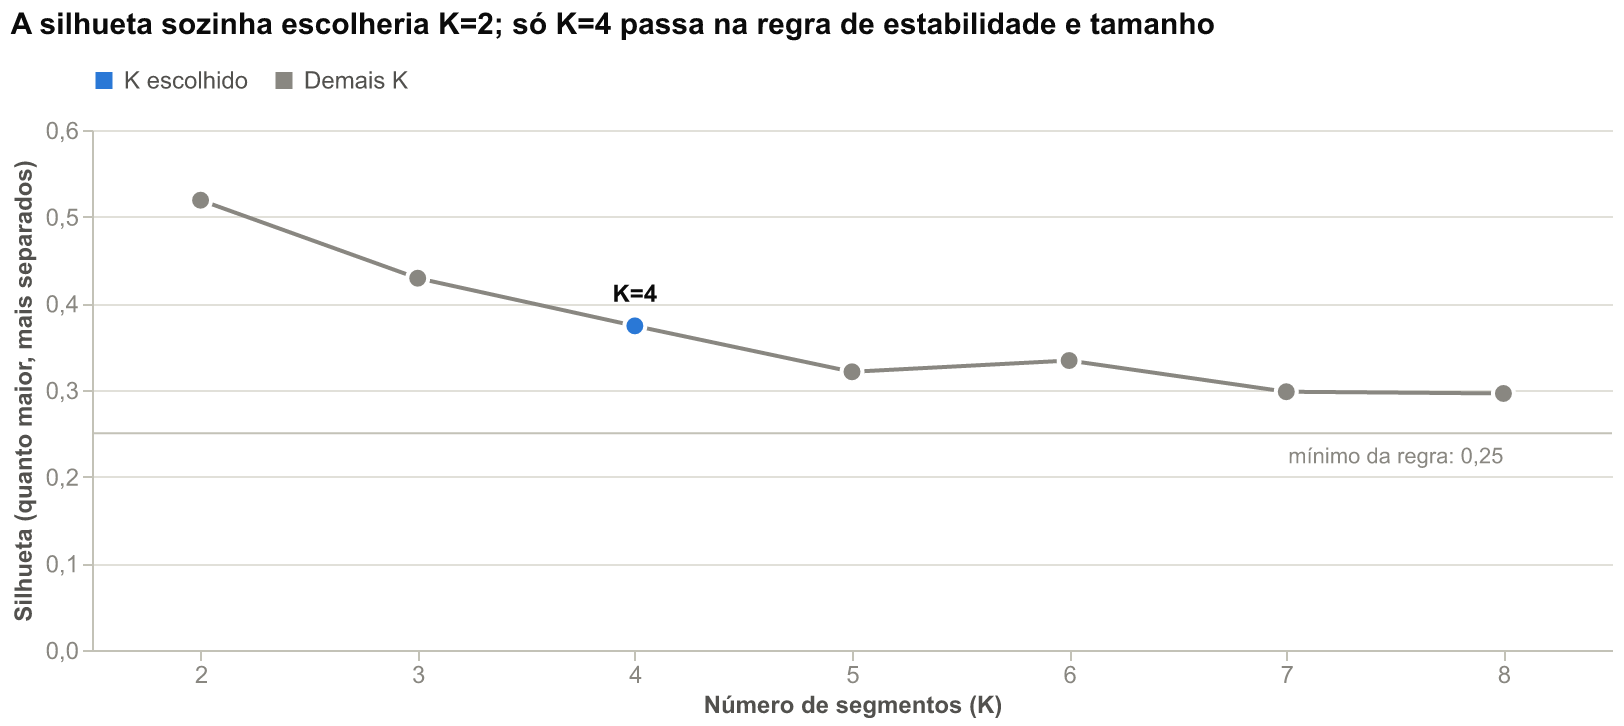

In [14]:
na.grafico(graficos.grafico_k(seg["avaliacao_k"], seg["k_usado"], cfg_rfm, na.MODO))

In [15]:
est = seg["estabilidade"]
na.md(f"**Estabilidade do K = {seg['k_usado']}:** ARI mínimo de {na.pt(est['ari_sementes_min'], 3)} entre {est['sementes']} sementes e de {na.pt(est['ari_subamostras_min'], 3)} entre "
      f"{est['subamostras']} subamostras de {int(est['fracao_subamostra'] * 100)}% dos clientes (1 = os mesmos grupos). A silhueta é {na.pt(seg['silhueta'], 2)}: "
      "há estrutura, mas **moderada**. Os segmentos são uma divisão útil de um contínuo, não ilhas separadas.")
perfil = na.tabela(seg["segmentos"], {"nome": "Segmento", "households": "Households", "pct_households": "% dos households", "recencia_media_dias": "Recência média (dias)",
                                      "frequencia_media": "Compras (média)", "valor_medio_usd": "Valor médio (US$)", "ticket_medio_usd": "Ticket médio (US$)",
                                      "pct_faturamento": "% do faturamento", "desconto_medio_pct": "Desconto (% do bruto)"},
                   {"pct_households": 1, "recencia_media_dias": 0, "frequencia_media": 1, "valor_medio_usd": 0, "ticket_medio_usd": 2, "pct_faturamento": 1, "desconto_medio_pct": 1})
perfil[["Segmento", "Households", "% dos households", "Recência média (dias)", "Compras (média)", "Valor médio (US$)", "Ticket médio (US$)", "% do faturamento", "Desconto (% do bruto)"]]

**Estabilidade do K = 4:** ARI mínimo de 0,971 entre 10 sementes e de 0,974 entre 10 subamostras de 80% dos clientes (1 = os mesmos grupos). A silhueta é 0,37: há estrutura, mas **moderada**. Os segmentos são uma divisão útil de um contínuo, não ilhas separadas.

,Segmento,Households,% dos households,Recência média (dias),Compras (média),Valor médio (US$),Ticket médio (US$),% do faturamento,Desconto (% do bruto)
0,Fiéis,857,35.4,3.0,56.0,1780.0,37.53,70.9,15.5
1,Regulares,980,40.5,11.0,18.1,568.0,35.48,25.9,16.2
2,Esporádicos,426,17.6,28.0,5.9,129.0,26.61,2.5,16.7
3,Em pausa,158,6.5,108.0,4.2,99.0,26.07,0.7,16.2


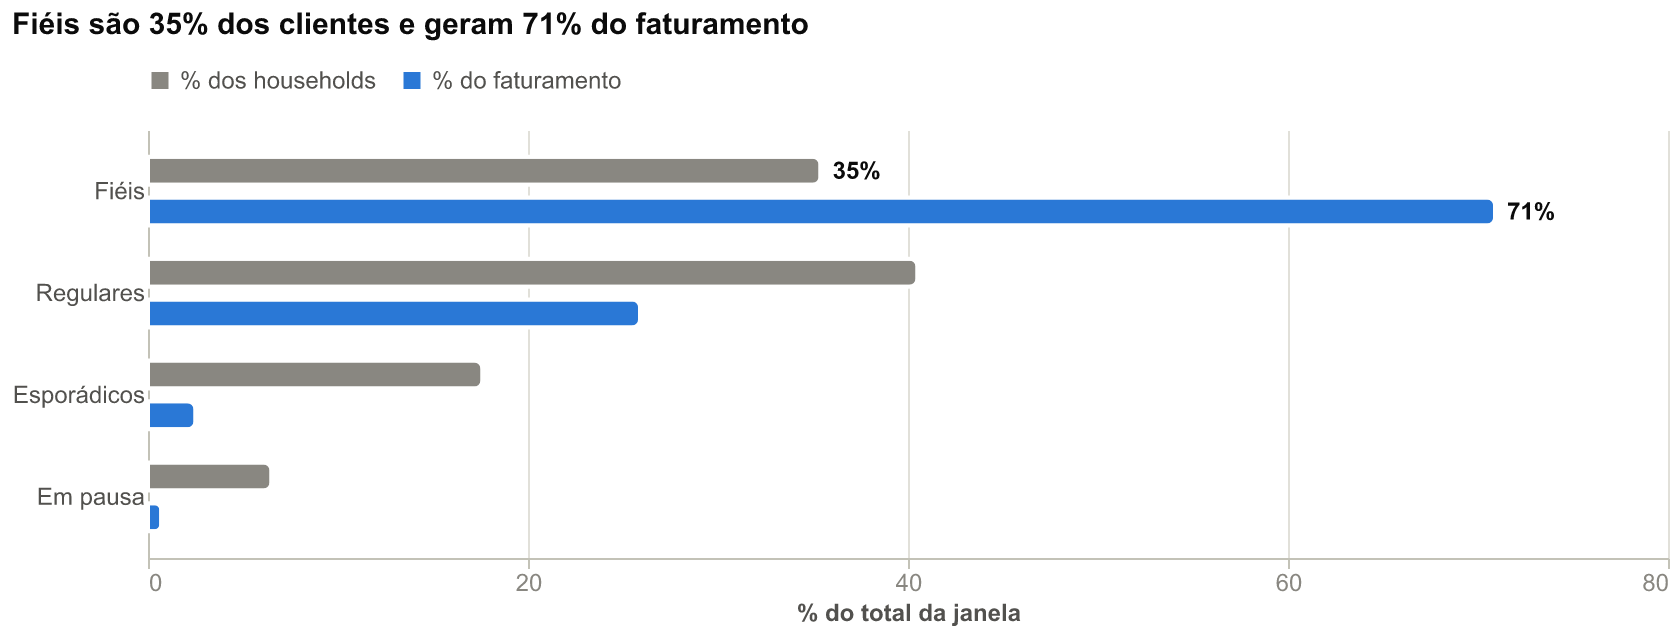

In [16]:
na.grafico(graficos.grafico_segmentos(seg["segmentos"], na.MODO))

### Households que ficam fora e retenção por coorte (análise de apoio)

A **coorte** é um apoio ao RFM, não um pilar: mostra se quem entrou no painel em momentos diferentes se comporta de forma parecida. Blocos de 4 semanas, coortes com menos de 30 households omitidas.
Ressalva importante: **entrada no painel não é cliente novo**. Quase todos os households aparecem nas primeiras 20 semanas do arquivo, então "coorte" aqui descreve a entrada no painel, não a aquisição de clientes.

**Fora da segmentação:** 79 households — sem compra na janela atual (pausa total: ficam fora da segmentação, mas entram no CLV como grupo próprio); 0 households — valor líquido <= 0 na janela (devolução maior que a compra).

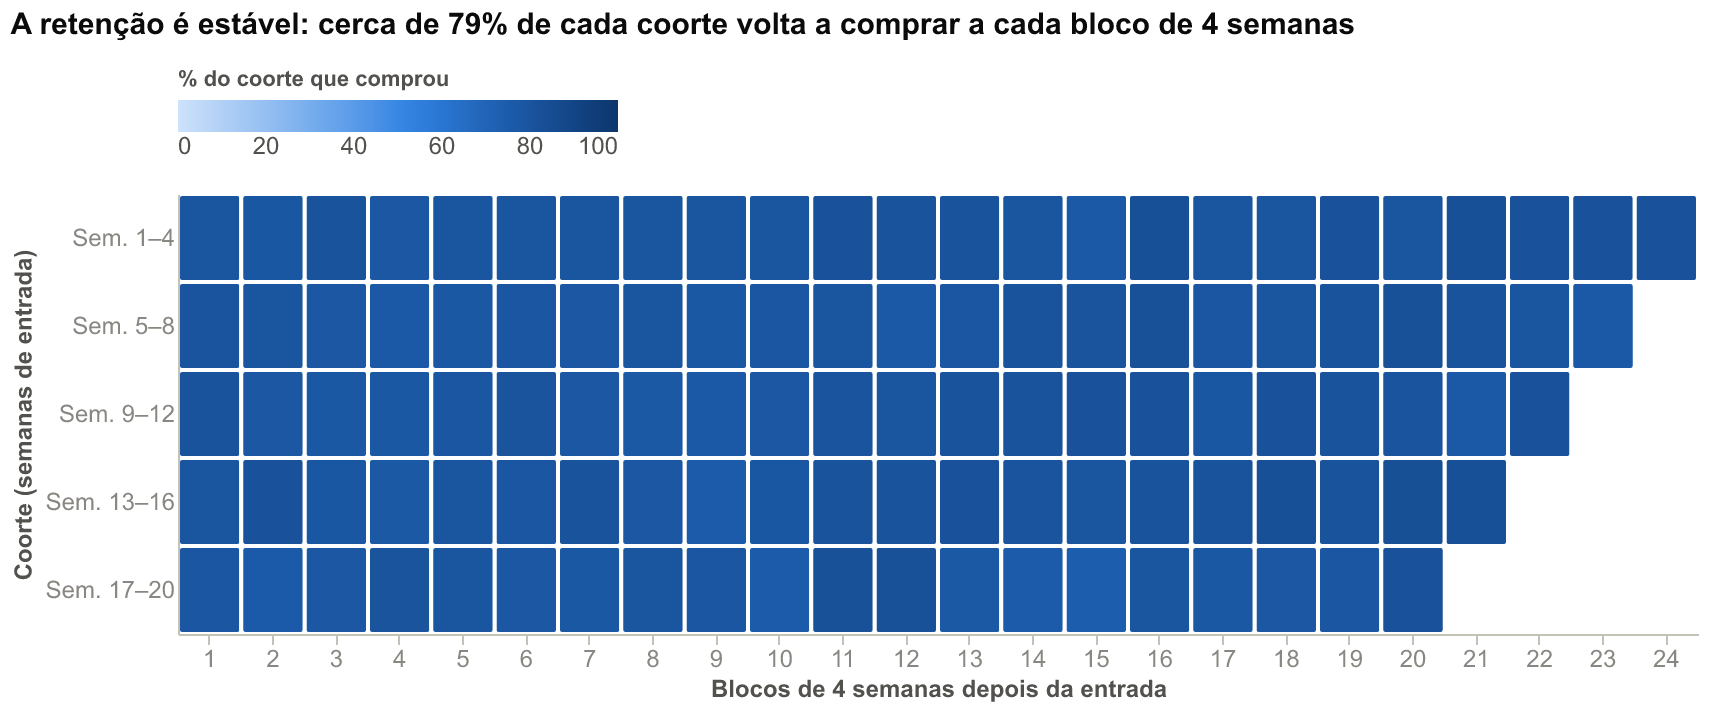

*Entrada = primeira compra no histórico. 99,2% dos households entram nas primeiras semanas (painel em formação), então a entrada não marca cliente novo e a retenção por coorte mostra, sobretudo, a constância do painel. 19 households de entrada tardia ficam fora por serem poucos demais para uma coorte.*

In [17]:
na.md("**Fora da segmentação:** " + "; ".join(f"{na.milhar(e['households'])} households — {e['motivo']}" for e in seg["excluidos"]) + ".")
na.grafico(graficos.grafico_coorte(coorte["coortes"], na.MODO))
na.md(f"*{coorte['limitacao']}*")

In [18]:
na.e_dai(seg["e_dai"])

> **E daí?**
>
> **Conclusão.** Fiéis são 35% dos households e fazem 71% do faturamento da janela; 4 segmentos, com estabilidade mínima de 0,97 (ARI).
>
> **Ação recomendada.** Fiéis: proteger com benefícios de fidelidade e acompanhar qualquer queda de frequência; Regulares: aumentar frequência e gasto por ida (ofertas cruzadas entre categorias); Esporádicos: reativar com ofertas de retorno antes que entrem em pausa longa.
>
> **Impacto estimado.** Fiéis geram US$ 1.525.211 por janela de 26 semanas; perder 5% deles custa cerca de US$ 76.261. Os Em pausa (158 households) geram hoje US$ 15.592 (0,7%) da janela; a aba de CLV mostra quanto voltam a valer.
>
> **Limitações.** Painel de 2.500 households frequentes, não o cliente médio do varejista; os segmentos descrevem as últimas 26 semanas e mudam com a janela. 79 households sem compra na janela ficam fora da segmentação (pausa total; entram no CLV como grupo próprio) e não aparecem como segmento. Silhueta de 0,37: estrutura moderada, as fronteiras entre segmentos são graduais. O K vem da regra combinada (silhueta, estabilidade, tamanho), não só da silhueta, que sozinha escolheria K=2. Segmento descreve comportamento, não causa.

## 4. CLV: quanto vale cada grupo

**Decisão que esta seção apoia:** quanto vale investir em cada grupo de clientes (fidelização, reativação), e onde o dinheiro de retenção rende mais?

### Método e premissas

O dataset não traz custo, então o "valor do cliente" aqui é **margem esperada nas próximas 52 semanas**, com premissas explícitas:

- **Gasto esperado.** Para cada household, o gasto médio das últimas 26 semanas vezes uma **razão futuro/passado**: quanto os clientes *do mesmo segmento* gastaram nas 52 semanas seguintes, comparado com as 26 anteriores,
  **um ano antes** (a coorte da janela-base, segmentada com o mesmo K e as mesmas regras de nome). Multiplicar o passado por 2 seria ingênuo: grupos de gasto baixo numa janela tendem a voltar ao seu nível normal
  (**regressão à média**), e grupos de gasto alto tendem a cair um pouco.
- **Margem de 25% é premissa**, não dado. O CLV escala linearmente com ela: com 20%, todos os valores caem 20%.
- **Households sem compra na janela** formam um grupo próprio ("Sem compra na janela"), estimado direto pelo que os households *análogos* gastaram depois, um ano antes. Sem isso o total ignoraria quem parou de comprar e depois voltou.
- **Intervalo de confiança de 95% por bootstrap de households** (2.000 reamostras, semente fixa), nas duas coortes. Ele mede só a variação entre households: **não** cobre a incerteza da margem nem a escolha dos segmentos.
- **Sem desconto financeiro** (taxa de juros): num horizonte de um ano ele mudaria pouco o ranking dos grupos.
- **Validação por backtest de 26 semanas:** calibra em um período, segmenta o seguinte e prevê o terceiro, que já foi observado. O horizonte de **52 semanas não tem backtest**: só existe uma transição anual observável.

In [19]:
prem = clv["premissas"]
na.md(f"**Premissas desta execução.** Método: {prem['metodo']}. Horizonte de {prem['horizonte_semanas']} semanas; margem de {prem['margem'] * 100:.0f}% (**premissa**: o dataset não tem custo). "
      f"Janela atual: {prem['janela_atual']}; calibração (um ano antes): {prem['janela_calibracao']}; semanas futuras observadas na calibração: {prem['semanas_futuras_observadas']}. "
      f"Bootstrap: {prem['bootstrap']['reamostras']} reamostras, nível de {prem['bootstrap']['nivel'] * 100:.0f}%, semente {prem['bootstrap']['semente']}. {prem['grupo_sem_compra']}.")
tab = pd.DataFrame([{"Grupo": s["nome"], "Households": s["n"], "Gasto médio nas 26 semanas (US$)": s["valor_medio_janela_usd"],
                     "Razão futuro/passado": s["razao_futuro_passado"], "CLV por household (US$)": s["clv_medio"],
                     "IC 95% (US$)": f"{na.milhar(s['ic_95'][0])} a {na.milhar(s['ic_95'][1])}", "Receita esperada (US$)": s["receita_esperada_usd"],
                     "Margem esperada do grupo (US$)": s["clv_total_usd"]} for s in clv["segmentos"]])
tab.round({"Gasto médio nas 26 semanas (US$)": 0, "Razão futuro/passado": 2, "CLV por household (US$)": 0, "Receita esperada (US$)": 0, "Margem esperada do grupo (US$)": 0})

**Premissas desta execução.** Método: CLV por household = margem x gasto médio das últimas semanas da janela x razão (gasto nas 52 semanas seguintes ÷ gasto nas semanas da janela) observada para o mesmo segmento um ano antes. Horizonte de 52 semanas; margem de 25% (**premissa**: o dataset não tem custo). Janela atual: semanas 76-101; calibração (um ano antes): semanas 24-49; semanas futuras observadas na calibração: 50-101. Bootstrap: 2000 reamostras, nível de 95%, semente 42. Sem compra na janela: gasto médio dos households sem compra na janela base nas 52 semanas seguintes.

,Grupo,Households,Gasto médio nas 26 semanas (US$),Razão futuro/passado,CLV por household (US$),IC 95% (US$),Receita esperada (US$),Margem esperada do grupo (US$)
0,Fiéis,857,1780.0,1.84,820.0,781 a 860,3279.0,702528.0
1,Regulares,980,568.0,2.30,326.0,309 a 344,1302.0,319094.0
2,Esporádicos,426,129.0,4.20,135.0,120 a 153,540.0,57544.0
3,Em pausa,158,99.0,4.16,103.0,79 a 133,411.0,16235.0
4,Sem compra na janela,79,0.0,NaN,99.0,78 a 122,396.0,7820.0


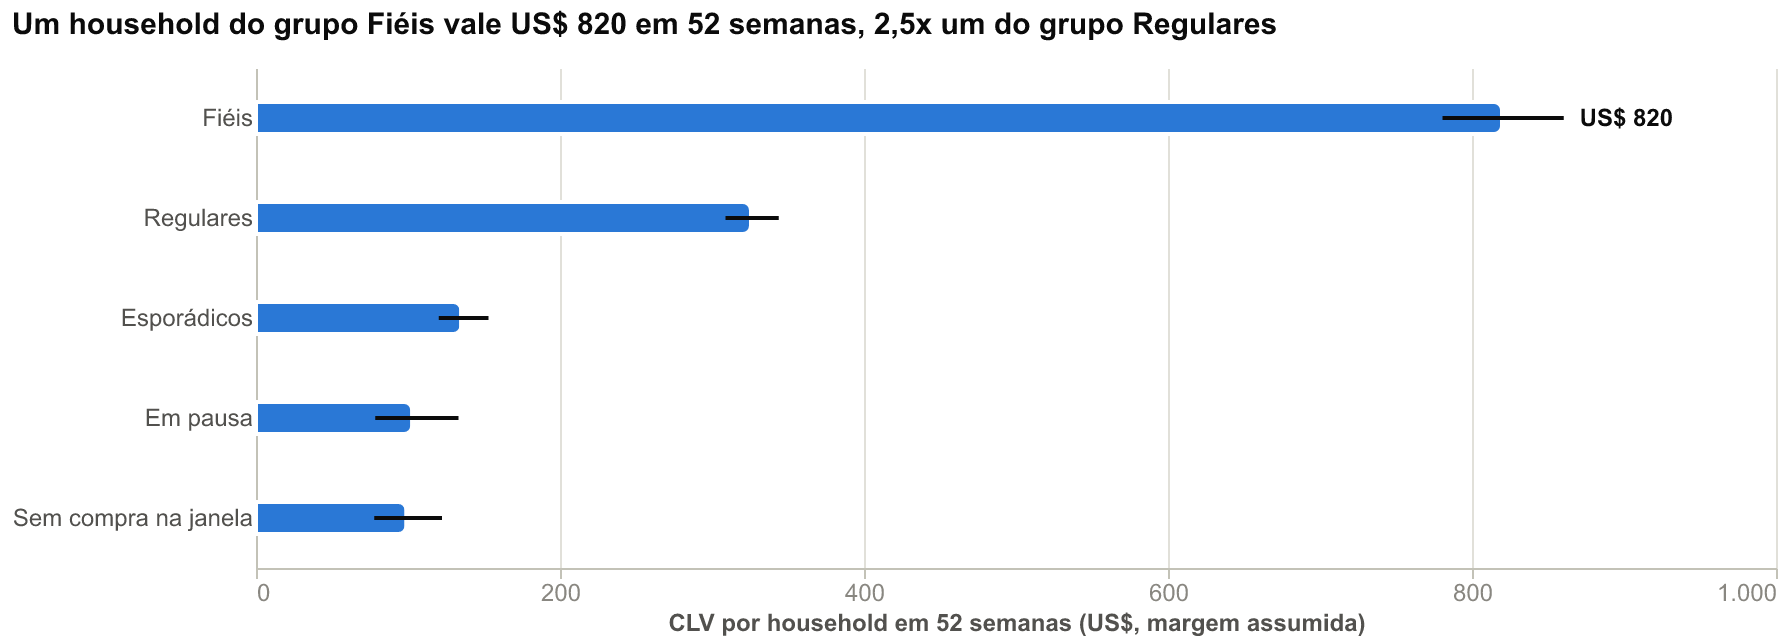

In [20]:
na.grafico(graficos.grafico_clv(clv["segmentos"], na.MODO))

### Por que os grupos de menor gasto valem mais do que o gasto passado sugere

A **razão futuro/passado** é o motor do método. Um ritmo de 1 significaria gastar nas próximas 52 semanas o mesmo ritmo das últimas 26. Os grupos de gasto baixo ficam acima disso: parte do gasto baixo numa janela
é acaso de calendário (quem comprou pouco *nessas* 26 semanas), não saída do cliente.

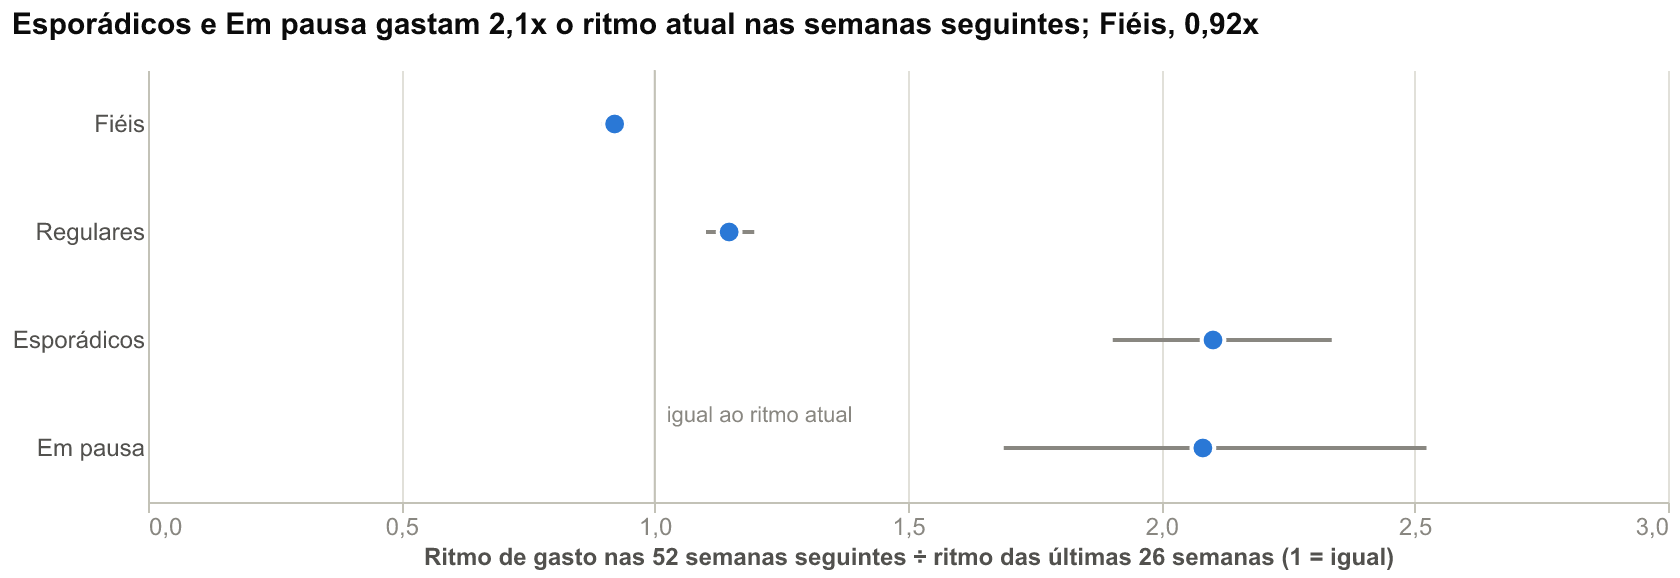

In [21]:
com_ritmo = [s for s in clv["segmentos"] if s.get("ritmo_relativo") is not None]
na.grafico(graficos.grafico_ritmo(com_ritmo, na.MODO))

### O método acerta? Backtest em 26 semanas

Aqui o futuro já aconteceu, então dá para comparar o previsto com o real e com uma **regra ingênua** ("repetir o último período"). Se o método não ganhasse da regra ingênua, o achado seria esse.

**Calibração:** semanas 24-49 -> 50-75. **Teste:** segmentos de 50-75 -> previsão de 76-101. No total, o método errou **2,9%** (a regra ingênua, 4,0%) e ganhou em **5 de 5** grupos. **Por household**, porém, o erro absoluto médio do método é US$ 321 contra US$ 317 da regra ingênua: **o CLV serve como média de grupo, não como previsão de um cliente.**

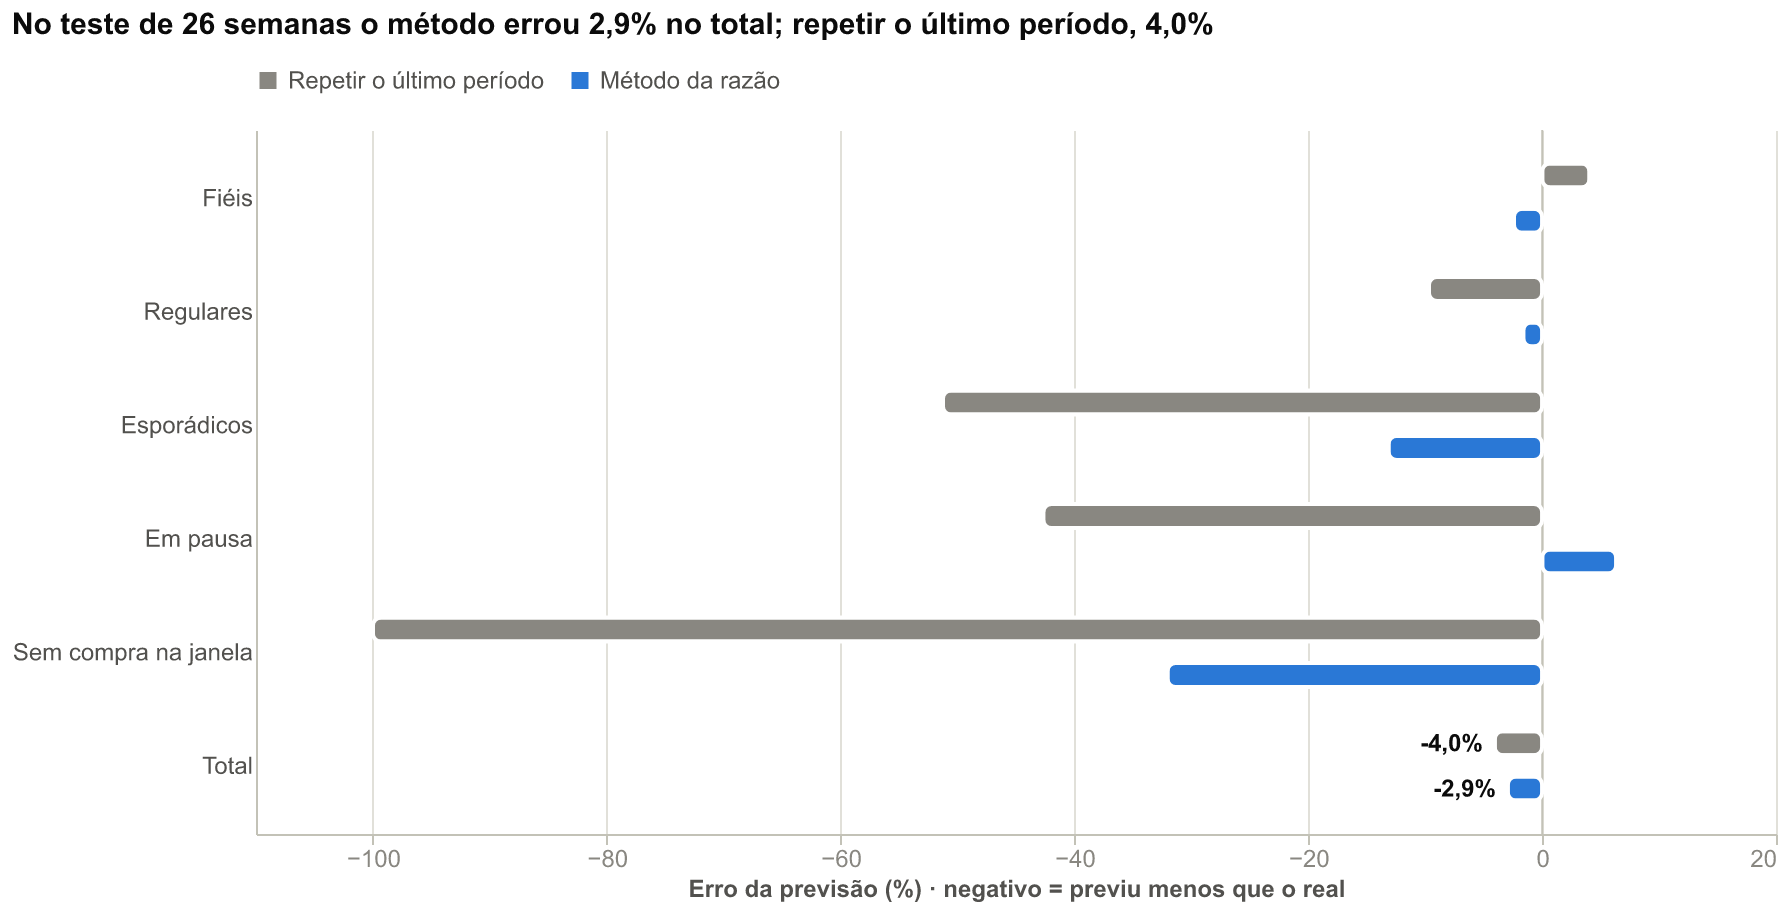

In [22]:
bt = clv["backtest"]
na.md(f"**Calibração:** {bt['calibracao']}. **Teste:** {bt['teste']}. No total, o método errou **{na.pt(abs(bt['total']['erro_metodo_pct']))}%** (a regra ingênua, {na.pt(abs(bt['total']['erro_ingenuo_pct']))}%) e ganhou em "
      f"**{bt['segmentos_em_que_o_metodo_ganha']} de {bt['segmentos_avaliados']}** grupos. **Por household**, porém, o erro absoluto médio do método é {na.usd(bt['mae_household_metodo_usd'])} contra "
      f"{na.usd(bt['mae_household_ingenuo_usd'])} da regra ingênua: **o CLV serve como média de grupo, não como previsão de um cliente.**")
na.grafico(graficos.grafico_backtest(bt, na.MODO))

In [23]:
na.e_dai(clv["e_dai"])

> **E daí?**
>
> **Conclusão.** Fiéis valem US$ 820 por household em 52 semanas (IC 95%: US$ 781 a US$ 860) e concentram 64% do valor esperado (US$ 1.103.220 de margem).
>
> **Ação recomendada.** Priorizar a retenção dos Fiéis: cada 1% de gasto perdido neles pesa mais que em qualquer outro grupo. Esporádicos e Em pausa tendem a gastar mais nas semanas seguintes do que no ritmo atual (ritmo de 2,1x): prefira ofertas de reativação seletivas a descontos amplos.
>
> **Impacto estimado.** Valor esperado total em 52 semanas: US$ 1.103.220 de margem (IC 95%: US$ 1.063.210 a US$ 1.143.641) sobre US$ 4.412.881 de receita, com margem assumida de 25%. Uma queda de 5% no gasto dos Fiéis custa cerca de US$ 35.126.
>
> **Limitações.** A margem de 25% é premissa (o dataset não tem custo): o CLV escala linearmente com ela. O horizonte de 52 semanas não pode ser testado: só há uma transição de 52 semanas observada, e ela pode não se repetir. No backtest de 26 semanas o método errou 2,9% no total (regra ingênua: 4,0%) e ganhou em 5 de 5 grupos; por household o erro absoluto médio foi US$ 321 contra US$ 317 da regra ingênua: o valor serve como média de grupo, não como previsão individual. O intervalo cobre só a variação entre households; não inclui a incerteza da margem nem a escolha dos segmentos. Razões altas nos grupos de menor gasto refletem em parte regressão à média (parte do gasto baixo de uma janela é acaso de calendário), sem desconto financeiro em 12 meses.

## 5. Risco de pausa ("churn"): quem vai parar de comprar

**Decisão que esta seção apoia:** quem abordar com uma ação de reativação e quem deixar em paz? Contato custa dinheiro e incomoda cliente que ia comprar de qualquer jeito.

### O que é "churn" aqui, e por que o nome engana

Varejo de supermercado **não tem contrato de cancelamento**: o cliente simplesmente deixa de aparecer. O corte tem de ser escolhido e justificado. Aqui, **churn é pausa longa: ficar 8 semanas sem comprar**.
Oito semanas (56 dias) é o mesmo limite que define "cliente ativo" e o grupo "Em pausa", e fica acima do intervalo habitual entre compras destes clientes (medido logo abaixo).

Mas a palavra "churn" sugere perda definitiva, e os dados dizem o contrário: **a maioria de quem pausa volta** (números abaixo). Por isso o texto fala em *pausa*, e a ação recomendada é *priorizar* contato, não "salvar clientes perdidos".

### Como o modelo é validado

- **Split temporal, nunca sorteio de linhas.** Um sorteio aleatório mistura semanas e deixa o modelo "ver o futuro" (o comportamento de um household na semana 80 ajuda a prever sua pausa na semana 78). O modelo treina em fotos antigas,
  o limiar de decisão é escolhido numa foto seguinte e a avaliação final usa duas fotos mais recentes, **com janelas de rótulo que não se sobrepõem**.
- **População de cada foto:** quem comprou nas últimas 8 semanas e tem pelo menos 16 semanas de histórico. Quem já está em pausa fica de fora (já aconteceu, não há o que prever) e é contado à parte.
- **Variáveis só com informação até a foto:** semanas desde a última compra, compras nas últimas 8 semanas (log), gasto nas últimas 26 semanas (log), semanas com compra nas últimas 26 e a maior pausa seguida nas últimas 26.
- **Regressão logística** padronizada e regularizada: interpretável, com poucos coeficientes cujo sinal precisa fazer sentido de negócio. O sinal de cada um é conferido contra a intuição, e **cinco variáveis em vez de dez**:
  com as dez, as variáveis eram quase colineares e "compras em 26 semanas" ganhava sinal contrário ao esperado, um artefato; com cinco, o poder de previsão é o mesmo e os sinais fazem sentido.
- **Contra uma regra simples:** "sem compra há k semanas ou mais = vai pausar", com k escolhido no treino. Se o modelo não ganhasse da regra, o achado seria esse.
- **Limiar de alerta** escolhido pelo maior F1 na foto de validação, e **intervalo de confiança** da diferença de AUC por bootstrap **de households** (o mesmo household aparece em mais de uma foto).

In [24]:
ret = churn["retorno_apos_pausa"]
pausa = churn["ja_em_pausa"]
p95, p99 = cur.execute("""WITH g AS (SELECT WEEK_NO - LAG(WEEK_NO) OVER (PARTITION BY household_key ORDER BY WEEK_NO) AS intervalo FROM vw_cliente_semana)
                          SELECT quantile_cont(intervalo, 0.95), quantile_cont(intervalo, 0.99) FROM g WHERE intervalo IS NOT NULL""").fetchone()
na.md(f"**Por que 8 semanas.** O intervalo entre duas semanas com compra do mesmo household tem p95 de {na.pt(p95, 0)} semanas e p99 de {na.pt(p99, 0)}: oito semanas fica acima do que quase todos fazem "
      "entre uma compra e outra, sem ser tão longo a ponto de só pegar quem já saiu.")
na.md(f"**Pausa não é saída.** Das {na.milhar(ret['pausas_observadas'])} pausas observadas nas fotos, **{na.pt(ret['taxa_pct'], 0)}% voltaram a comprar em até {ret['janela_semanas']} semanas** "
      f"(entre {na.pt(ret['minimo_por_foto_pct'], 0)}% e {na.pt(ret['maximo_por_foto_pct'], 0)}% conforme a foto). **Definição usada:** {churn['definicao_churn']}")
na.md(f"**Fora da previsão:** {na.milhar(pausa['households'])} households já estão em pausa hoje ("
      + ", ".join(f"{k}: {na.milhar(v)}" for k, v in pausa["por_segmento"].items()) + ").")

**Por que 8 semanas.** O intervalo entre duas semanas com compra do mesmo household tem p95 de 5 semanas e p99 de 13: oito semanas fica acima do que quase todos fazem entre uma compra e outra, sem ser tão longo a ponto de só pegar quem já saiu.

**Pausa não é saída.** Das 1.338 pausas observadas nas fotos, **80% voltaram a comprar em até 18 semanas** (entre 71% e 85% conforme a foto). **Definição usada:** Sem compra nas próximas 8 semanas (pausa longa), entre quem comprou nas últimas 8 semanas e tem ao menos 16 semanas de histórico. 8 semanas = 56 dias, o mesmo limite de "cliente ativo" e de "Em pausa".

**Fora da previsão:** 297 households já estão em pausa hoje (Em pausa: 158, Sem compra na janela: 79, Esporádicos: 46, Regulares: 14).

In [25]:
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from src.nucleo import churn as nucleo_churn

fim = seg["janela"]["atual"]["semanas"][1]
plano = nucleo_churn.fotos_do_plano(fim)
painel = nucleo_churn.carregar_painel(cur, fim)
h = CFG["analises"]["churn"]["horizonte_semanas"]
na.md(f"**Plano de fotos (semanas):** treino {plano['treino'][0]} a {plano['treino'][-1]} a cada {CFG['analises']['churn']['treino_passo_semanas']} (rótulos até a semana {plano['treino'][-1] + h}); "
      f"validação {plano['validacao']} (rótulos {plano['validacao'] + 1} a {plano['validacao'] + h}); teste {plano['teste'][0]} e {plano['teste'][1]} "
      f"(rótulos {plano['teste'][0] + 1} a {plano['teste'][0] + h} e {plano['teste'][1] + 1} a {plano['teste'][1] + h}). Nenhum rótulo se sobrepõe à foto seguinte; o código recusa um plano que se sobreponha.")
X = np.vstack([nucleo_churn.fotografar(painel, T, com_rotulo=False)[0] for T in plano["treino"]])
Xz = np.column_stack([np.ones(len(X)), (X - X.mean(axis=0)) / X.std(axis=0)])
vif = pd.DataFrame({"Variável": [nucleo_churn.LEITURA[v] for v in nucleo_churn.VARIAVEIS],
                    "VIF": [variance_inflation_factor(Xz, i + 1) for i in range(X.shape[1])]}).round(1)
na.md(f"**Colinearidade entre as {len(nucleo_churn.VARIAVEIS)} variáveis (VIF nas {na.milhar(len(X))} linhas de treino).** Valores acima de 5 a 10 indicam variáveis que se explicam entre si; aqui o maior é {na.pt(vif['VIF'].max(), 1)}. "
      "Há colinearidade residual: o coeficiente de cada variável deve ser lido como o da variável dominante do grupo, e o conjunto, como associação, não como causa.")
vif

**Plano de fotos (semanas):** treino 30 a 66 a cada 4 (rótulos até a semana 74); validação 77 (rótulos 78 a 85); teste 85 e 93 (rótulos 86 a 93 e 94 a 101). Nenhum rótulo se sobrepõe à foto seguinte; o código recusa um plano que se sobreponha.

**Colinearidade entre as 5 variáveis (VIF nas 21.318 linhas de treino).** Valores acima de 5 a 10 indicam variáveis que se explicam entre si; aqui o maior é 7,2. Há colinearidade residual: o coeficiente de cada variável deve ser lido como o da variável dominante do grupo, e o conjunto, como associação, não como causa.

,Variável,VIF
0,semanas desde a última compra,1.5
1,compras nas últimas 8 semanas,3.8
2,gasto nas últimas 26 semanas,2.9
3,semanas com compra nas últimas 26 (constância),7.2
4,maior pausa seguida nas últimas 26 semanas,3.3


### O modelo ganha da regra simples?

In [26]:
m, b = churn["modelo"], churn["baseline"]
comparacao = pd.DataFrame({"Medida": ["AUC", "AUC-PR (a prevalência é pequena)", "Precisão (alertas que se confirmam)", "Recall (pausas que o alerta pega)", "F1", "Alertas disparados"],
                           "Modelo": [m["auc"], m["auc_pr"], m["precisao"], m["recall"], m["f1"], m["alertas"]],
                           "Regra simples": [b["auc"], b["auc_pr"], b["precisao"], b["recall"], b["f1"], b["alertas"]]}).round(3)
lo, hi = churn["diferenca_auc_ic"]
mc = churn["matriz_confusao"]
na.md(f"{churn['baseline_descricao']}. **Prevalência de pausas no teste: {na.pt(churn['prevalencia_pct']['teste'])}%** (por isso a acurácia seria enganosa: um modelo que nunca alerta acertaria {na.pt(100 - churn['prevalencia_pct']['teste'])}%). "
      f"A diferença de AUC é de **{na.pt(churn['diferenca_auc'], 3)}** (IC de 95% por household: {na.pt(lo, 3)} a {na.pt(hi, 3)}), com o limiar {na.pt(churn['limiar'], 2)} escolhido na validação. "
      f"Matriz de confusão do modelo no teste: {na.milhar(mc['modelo']['tp'])} verdadeiros positivos, {na.milhar(mc['modelo']['fp'])} falsos positivos, {na.milhar(mc['modelo']['fn'])} falsos negativos e {na.milhar(mc['modelo']['tn'])} verdadeiros negativos.")
comparacao

Regra simples: sem compra há 4 semanas ou mais = vai pausar (k escolhido no treino). **Prevalência de pausas no teste: 6,4%** (por isso a acurácia seria enganosa: um modelo que nunca alerta acertaria 93,6%). A diferença de AUC é de **0,115** (IC de 95% por household: 0,089 a 0,149), com o limiar 0,17 escolhido na validação. Matriz de confusão do modelo no teste: 136 verdadeiros positivos, 337 falsos positivos, 147 falsos negativos e 3.805 verdadeiros negativos.

,Medida,Modelo,Regra simples
0,AUC,0.853,0.738
1,AUC-PR (a prevalência é pequena),0.272,0.177
2,Precisão (alertas que se confirmam),0.288,0.232
3,Recall (pausas que o alerta pega),0.481,0.332
4,F1,0.360,0.273
5,Alertas disparados,473.000,405.000


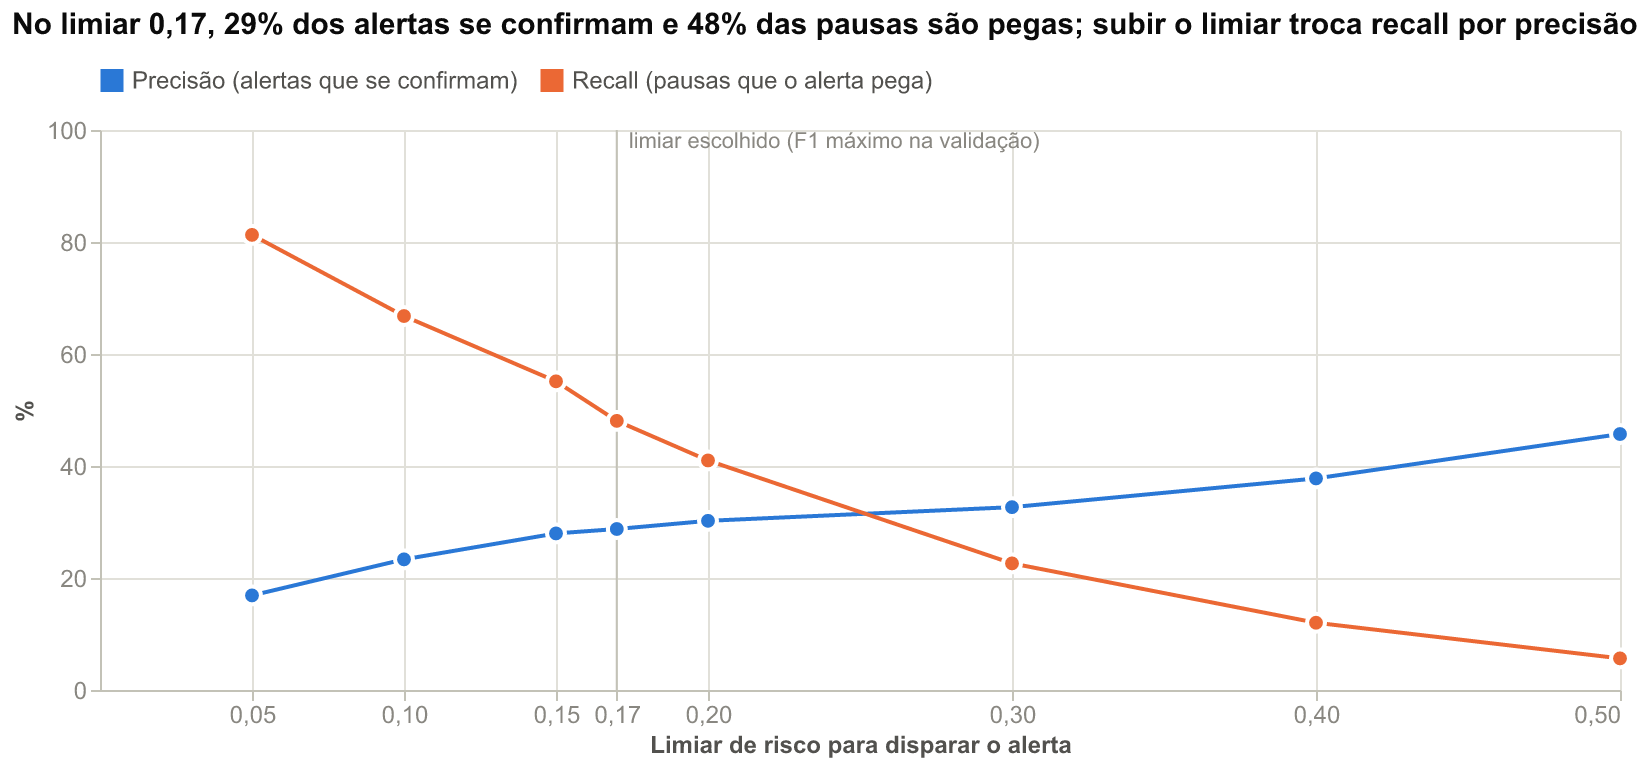

In [27]:
na.grafico(graficos.grafico_limiar(churn["curva_limiar"], na.MODO))

### As probabilidades são confiáveis? E o que pesa no risco?

A **calibração** compara o risco previsto com a frequência observada por decil de risco: se o modelo diz 30%, tem de acontecer em cerca de 30% dos casos, senão a probabilidade não serve para calcular quanto dinheiro está em jogo.
Os **fatores** são odds ratios por desvio-padrão: abaixo de 1 reduzem o risco, acima de 1 aumentam. São **associação, não causa**.

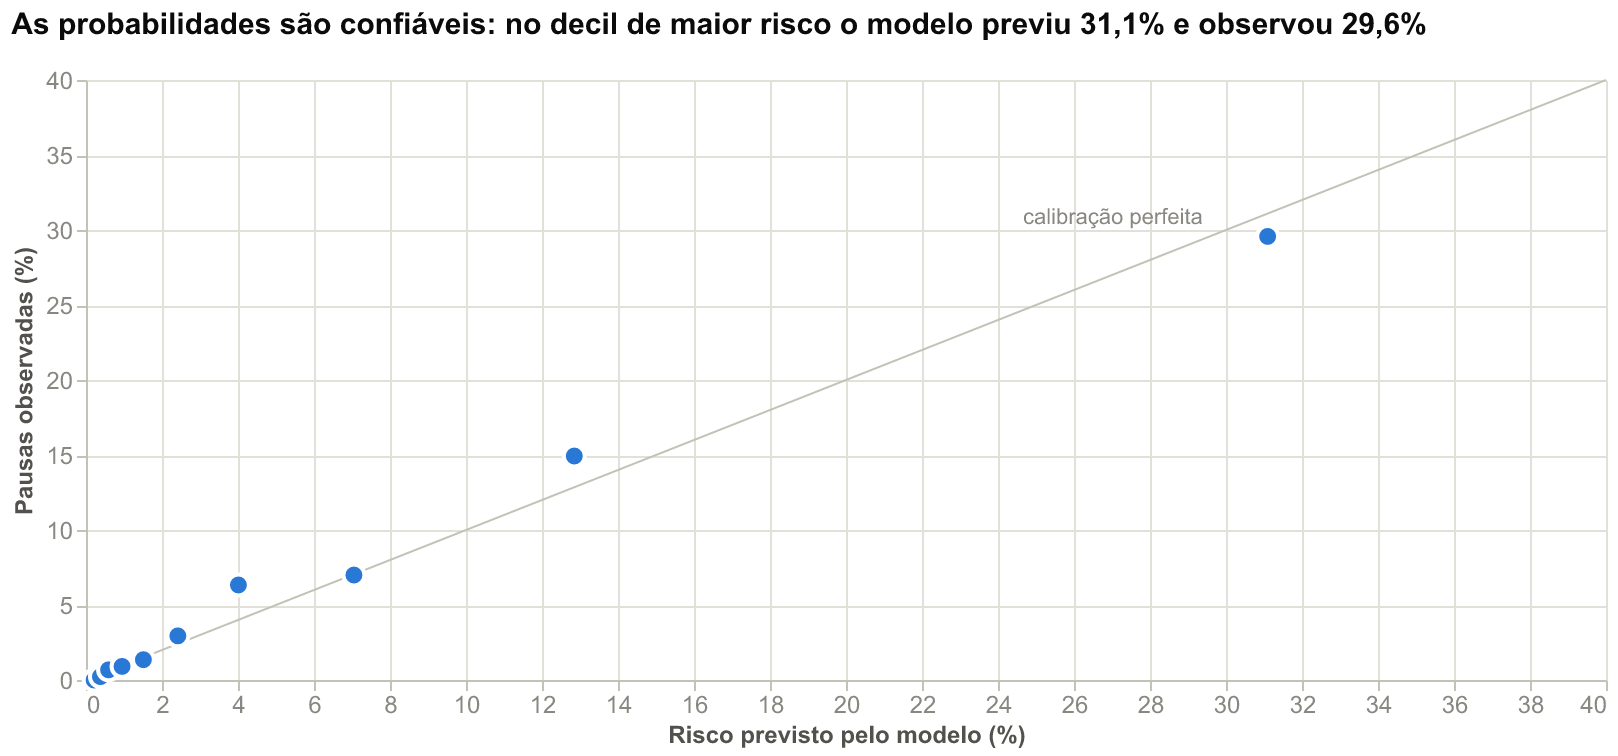

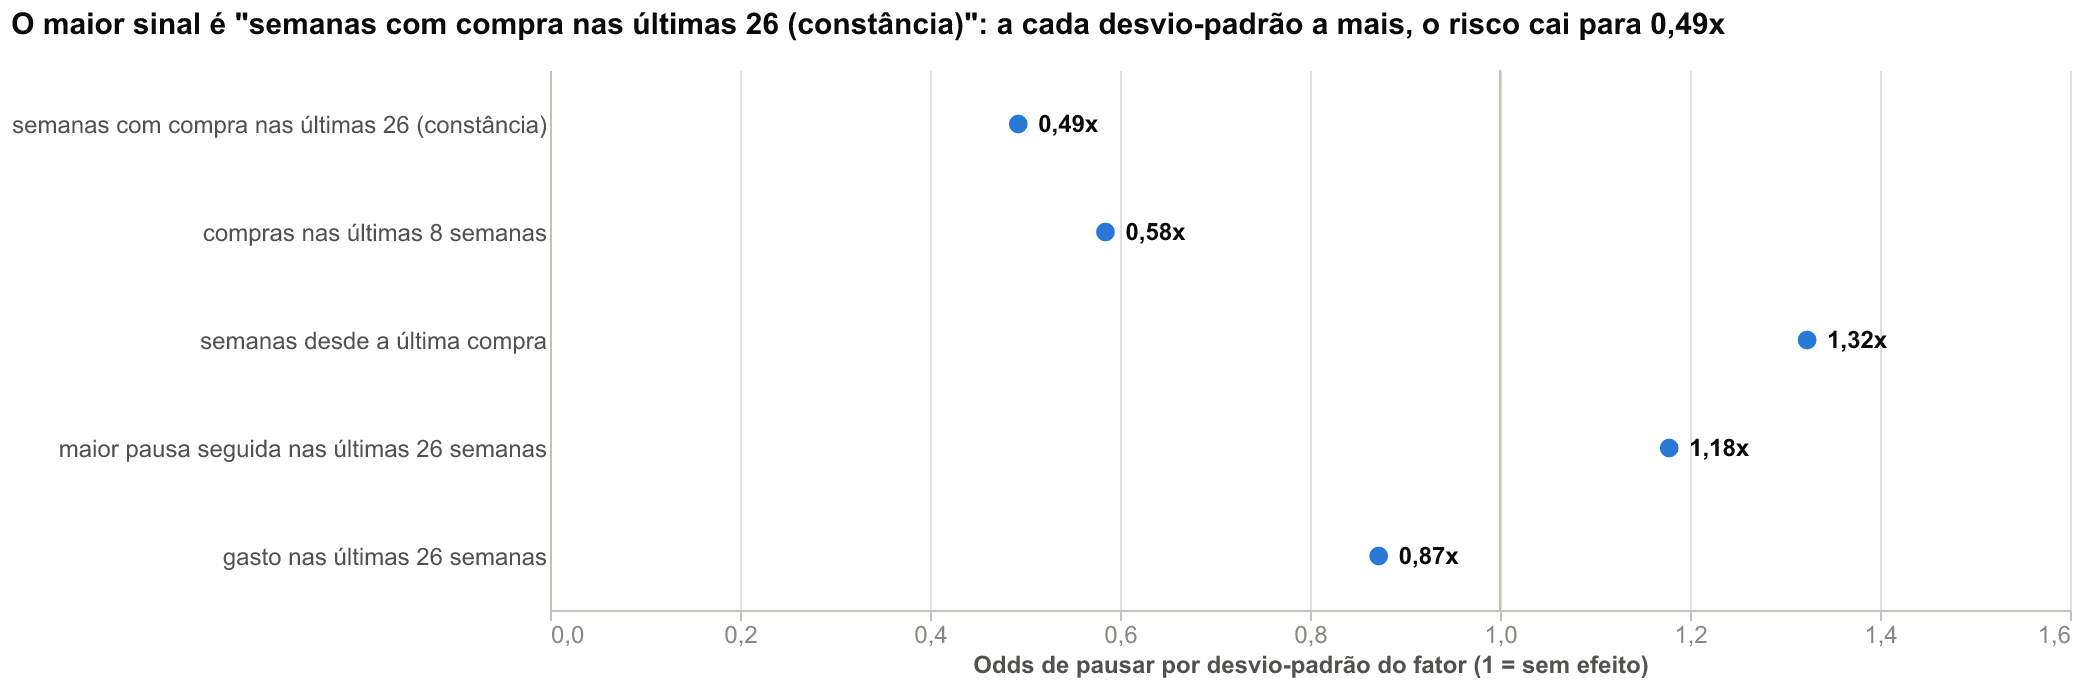

In [28]:
na.grafico(graficos.grafico_calibracao(churn["calibracao"], na.MODO))
na.grafico(graficos.grafico_fatores(churn["principais_fatores"], na.MODO))

### Onde estão as pausas, e onde está o dinheiro

O risco se concentra em quem compra pouco. Mas o **valor em risco** (risco × gasto semanal × 8 semanas) pesa o quanto cada cliente gasta, e isso muda quem é a prioridade.

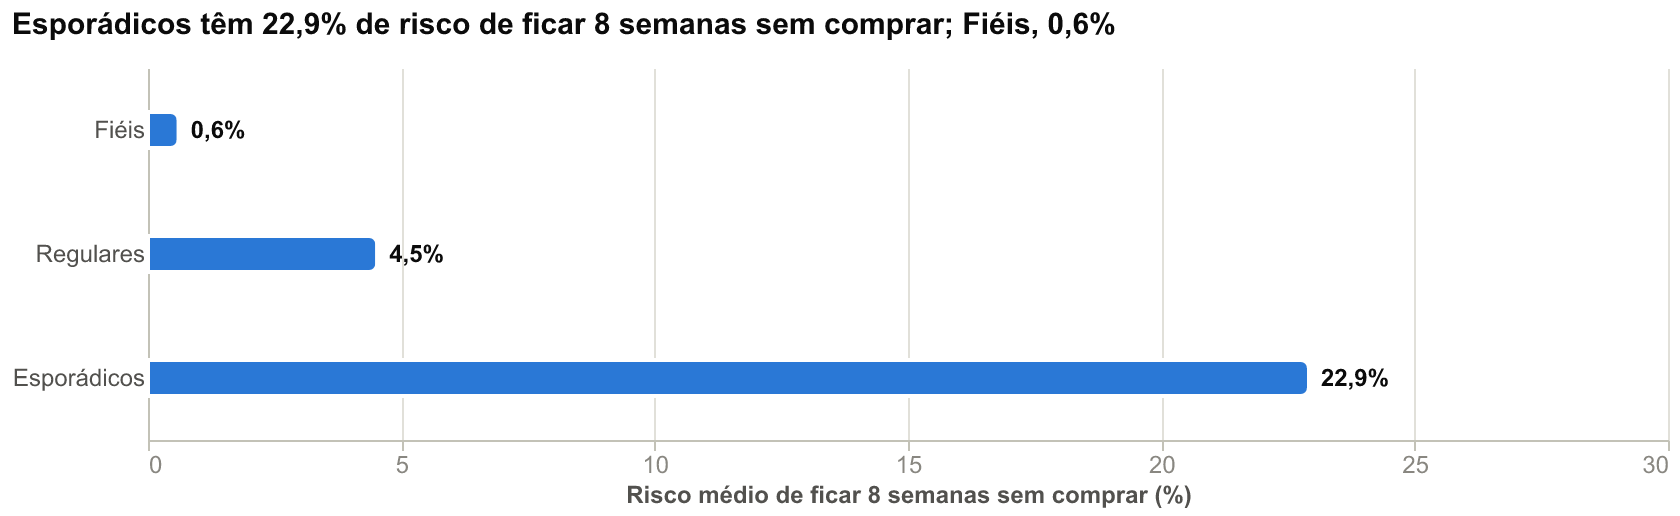

,Segmento,Households,Risco médio (%),Pausas esperadas,% das pausas,Em alerta hoje,Valor em risco (US$),% do valor em risco
0,Fiéis,857,0.6,5.2,3.8,0,2517.3,19.8
1,Regulares,966,4.5,43.7,32.1,20,7157.4,56.3
2,Esporádicos,380,22.9,87.1,64.0,223,3031.4,23.9


In [29]:
risco = graficos.tabela_risco(churn["risco_por_segmento"])
na.grafico(graficos.grafico_risco(churn["risco_por_segmento"], churn["horizonte_semanas"], na.MODO))
risco.rename(columns={"segmento": "Segmento", "households": "Households", "risco_medio_pct": "Risco médio (%)", "pausas_esperadas": "Pausas esperadas",
                      "pct_das_pausas": "% das pausas", "alertas": "Em alerta hoje", "valor_em_risco_usd": "Valor em risco (US$)",
                      "pct_do_valor_em_risco": "% do valor em risco"}).round(1)

In [30]:
na.e_dai(churn["e_dai"])

> **E daí?**
>
> **Conclusão.** Cerca de 136 dos 2.203 households ativos devem passar 8 semanas sem comprar; Esporádicos concentram 64% dessas pausas (risco médio de 22,9%, contra 0,6% dos Fiéis). O modelo ordena melhor que a regra de recência (AUC 0,85 contra 0,74).
>
> **Ação recomendada.** Fazer reativação seletiva nos 243 households em alerta hoje (limiar 0,17): as pausas se concentram nos Esporádicos, mas o dinheiro em risco está nos Regulares (56% do valor em risco). Cada alerta acerta 29% das vezes e o conjunto pega 48% das pausas. Não gastar com Fiéis (risco de 0,6%).
>
> **Impacto estimado.** Faturamento em risco nas próximas 8 semanas ≈ US$ 12.706, calculado como risco x gasto semanal x 8, ou 1,9% do faturamento esperado do período. Como 80% de quem pausa volta em até 18 semanas, a perda efetiva tende a ser menor.
>
> **Limitações.** Pausa não é saída: 80% voltam em 18 semanas, então o nome "churn" vale como pausa longa de 8 semanas. A população é quem comprou nas últimas 8 semanas e tem ao menos 16 semanas de histórico; 297 households já estão em pausa e ficam fora da previsão. Precisão modesta: de cada 100 alertas, 29 se confirmam. O modelo usa só comportamento de compra e mostra associação, não causa. O treino repete households em várias fotos (o intervalo é por household no teste). Os segmentos mudam com a janela.

## 6. Teste de hipótese: o desconto muda de um segmento para outro?

**Decisão que esta seção apoia:** a política de desconto deve variar por segmento? Se os grupos recebem descontos muito diferentes, vale perguntar por quê; se recebem o mesmo, não há o que ajustar por grupo.

**Hipótese escrita antes de rodar:** os segmentos recebem desconto **parecido**. O desconto vem sobretudo do cartão de fidelidade e de cupons, que são generalistas.

### Método e escolhas estatísticas

- **Variável:** % de desconto de cada household na janela atual = 100 × soma do desconto ÷ soma do valor bruto (a mesma definição das views). Os quatro segmentos do RFM são os grupos.
- **Teste não paramétrico.** O teste de Shapiro-Wilk, por grupo, mostra se o % de desconto é normal. Se não for, ANOVA não se justifica e usa-se **Kruskal-Wallis**, que compara as distribuições sem supor normalidade.
- **Post-hoc só se o teste geral for significativo:** Mann-Whitney par a par com **correção de Holm** para as seis comparações (sem a correção, a chance de um falso positivo em seis testes passa de 26%).
- **Significância não basta.** Com mais de 2.400 households, quase qualquer diferença vira "significativa". Por isso o veredito exige também **tamanho de efeito** (eta² do Kruskal-Wallis) e a diferença de medianas com
  **intervalo de confiança por bootstrap**. Regra escrita antes de rodar (`analises.teste_desconto` no `config.yaml`): *relevante* se eta² ≥ 1% **ou** se algum par tem diferença de medianas ≥ 1 ponto percentual com IC que exclui zero;
  *desprezível* se é significativo mas não passa disso; *sem diferença detectável* se p ≥ 0,05.
- **Sensibilidade.** O % de desconto de quem comprou poucas vezes vem de poucas cestas e varia muito. O teste é repetido **só com households de 5 ou mais compras**: se o veredito mudar, o resultado depende desse ruído.
- As funções do teste (normalidade, Kruskal-Wallis, post-hoc) são genéricas (recebem os nomes das colunas) e ficam em `src/teste_hipotese.py`; um teste confere o código-fonte delas. O que é específico deste projeto é só a preparação dos dados.

In [31]:
VEREDITO = {"sem_diferenca_detectavel": "sem diferença detectável", "diferenca_desprezivel": "diferença desprezível", "diferenca_relevante": "diferença relevante"}
norm = na.tabela(desc["normalidade_por_grupo"], {"segmento": "Segmento", "n": "Households", "shapiro_p_valor": "p-valor (Shapiro-Wilk)", "normal_a_5pct": "Normal a 5%?"})
na.md(f"**Normalidade:** {int((~norm['Normal a 5%?']).sum())} dos {len(norm)} grupos rejeitam a normalidade, então o teste não paramétrico se justifica.")
norm

**Normalidade:** 4 dos 4 grupos rejeitam a normalidade, então o teste não paramétrico se justifica.

,Segmento,Households,p-valor (Shapiro-Wilk),Normal a 5%?
0,Em pausa,158,0.0021,False
1,Esporádicos,426,0.0000,False
2,Fiéis,857,0.0000,False
3,Regulares,980,0.0000,False


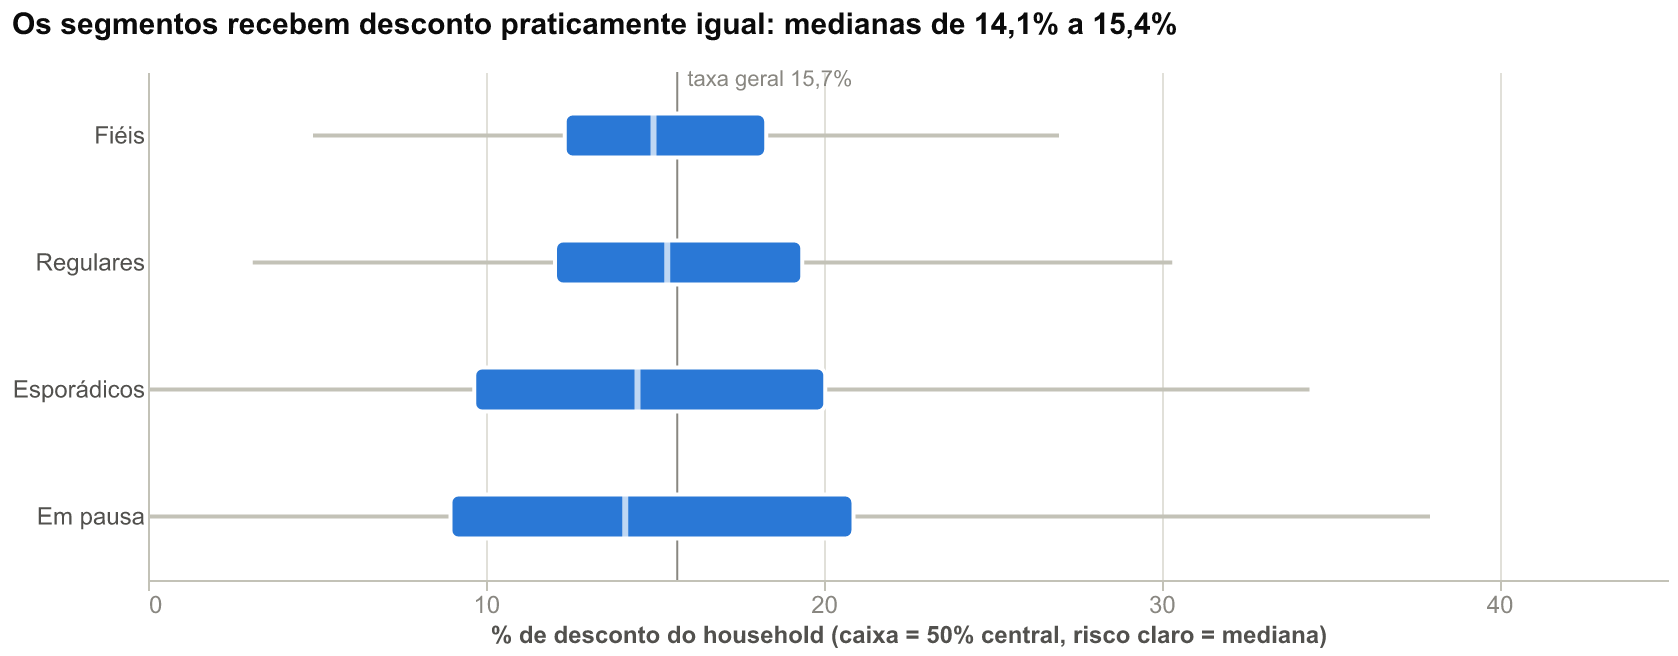

In [32]:
na.grafico(graficos.grafico_distribuicao(desc["grupos"], desc["veredito"], desc["impacto"]["taxa_geral_pct"], na.MODO))

In [33]:
kw = desc["kruskal_wallis"]
na.md(f"**Kruskal-Wallis:** H = {na.pt(kw['estatistica_H'], 2)}, p = {na.pt(kw['p_valor'], 4)}, **eta² = {na.pt(kw['eta_quadrado_aprox'], 4)}** ({na.pt(100 * kw['eta_quadrado_aprox'], 1)}% da variação), "
      f"{kw['n_grupos_testados']} grupos e {na.milhar(kw['n_total_observacoes'])} households. **Veredito pela regra escrita antes:** {VEREDITO[desc['veredito']]}.")
if desc["post_hoc_executado"]:
    ph = na.tabela(desc["post_hoc"], {"grupo_1": "Grupo 1", "grupo_2": "Grupo 2", "mediana_1": "Mediana 1 (%)", "mediana_2": "Mediana 2 (%)", "p_valor_bruto": "p bruto",
                                      "p_valor_ajustado": "p ajustado (Holm)", "significativo_5pct": "Significativo a 5%?"})
    na.md("**Comparações par a par (Mann-Whitney com correção de Holm)** — o teste geral foi significativo, então o post-hoc roda:")
else:
    ph = None
    na.md(f"Post-hoc não executado: {desc['post_hoc_motivo']}.")
ph.round({"p bruto": 4}) if ph is not None else None

**Kruskal-Wallis:** H = 11,68, p = 0,0085, **eta² = 0,0036** (0,4% da variação), 4 grupos e 2.421 households. **Veredito pela regra escrita antes:** diferença desprezível.

**Comparações par a par (Mann-Whitney com correção de Holm)** — o teste geral foi significativo, então o post-hoc roda:

,Grupo 1,Grupo 2,Mediana 1 (%),Mediana 2 (%),p bruto,p ajustado (Holm),Significativo a 5%?
0,Esporádicos,Regulares,14.49,15.38,0.0027,0.0164,True
1,Esporádicos,Fiéis,14.49,14.97,0.0194,0.0970,False
2,Em pausa,Regulares,14.13,15.38,0.0702,0.2809,False
3,Em pausa,Fiéis,14.13,14.97,0.1527,0.4580,False
4,Fiéis,Regulares,14.97,15.38,0.2032,0.4580,False
5,Em pausa,Esporádicos,14.13,14.49,0.9522,0.9522,False


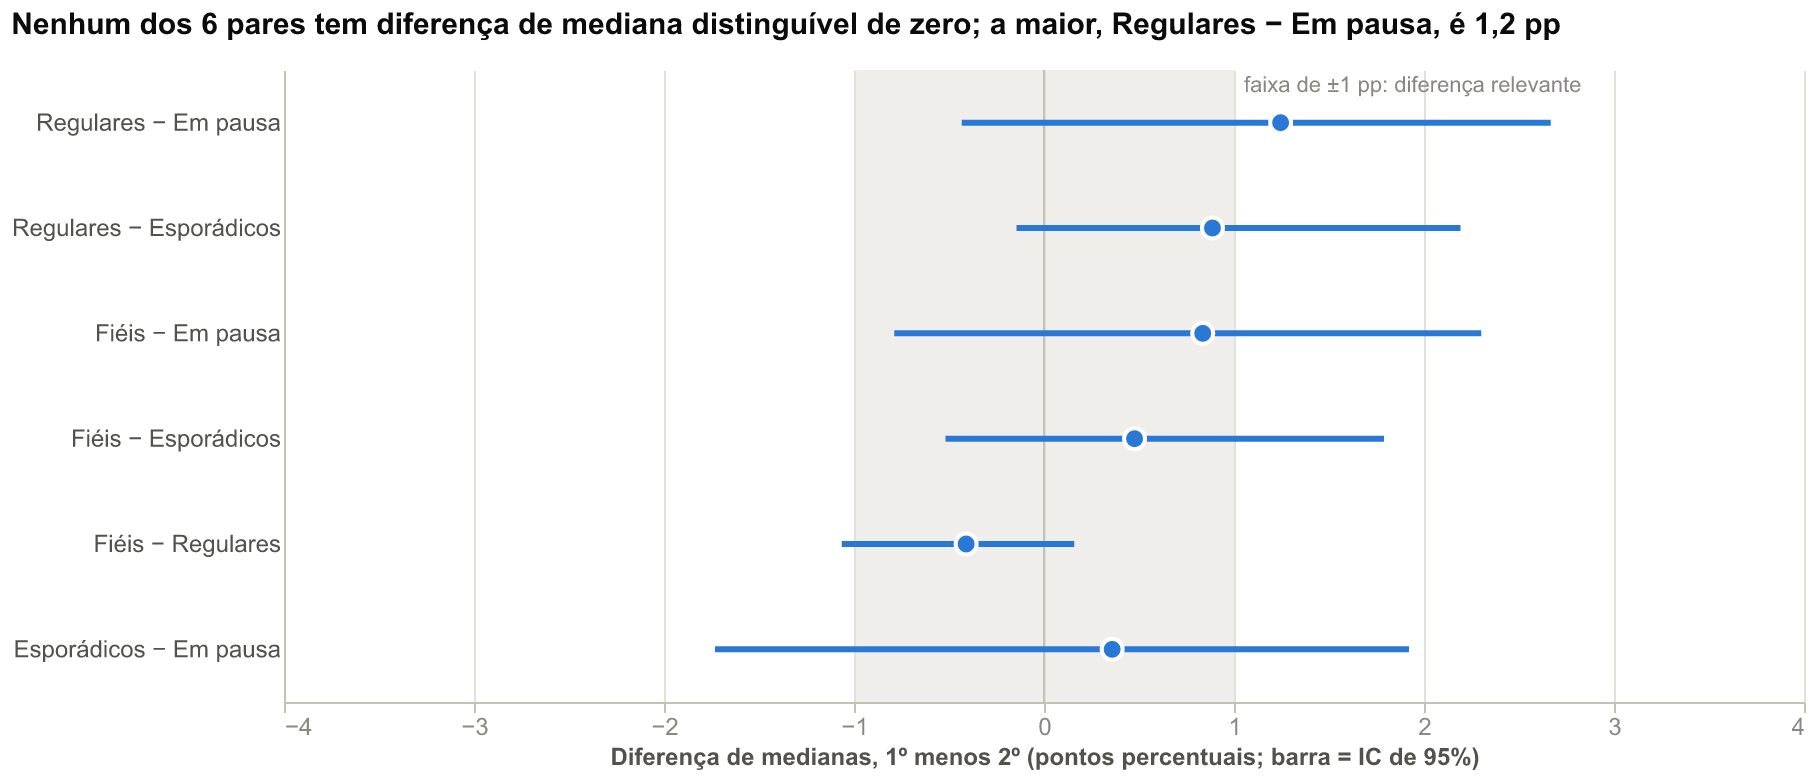

In [34]:
na.grafico(graficos.grafico_pares(desc["ic_diferencas"], CFG["analises"]["teste_desconto"]["diferenca_relevante_pp"], na.MODO))

### O resultado depende de quem comprou pouco?

Com 2.138 households de 5 ou mais compras (de 2.421): p = 0,5225, eta² = 0,0000, veredito **sem diferença detectável**. Quando a significância some ao tirar o ruído de poucas cestas, a diferença do teste completo não é uma política diferente por segmento.

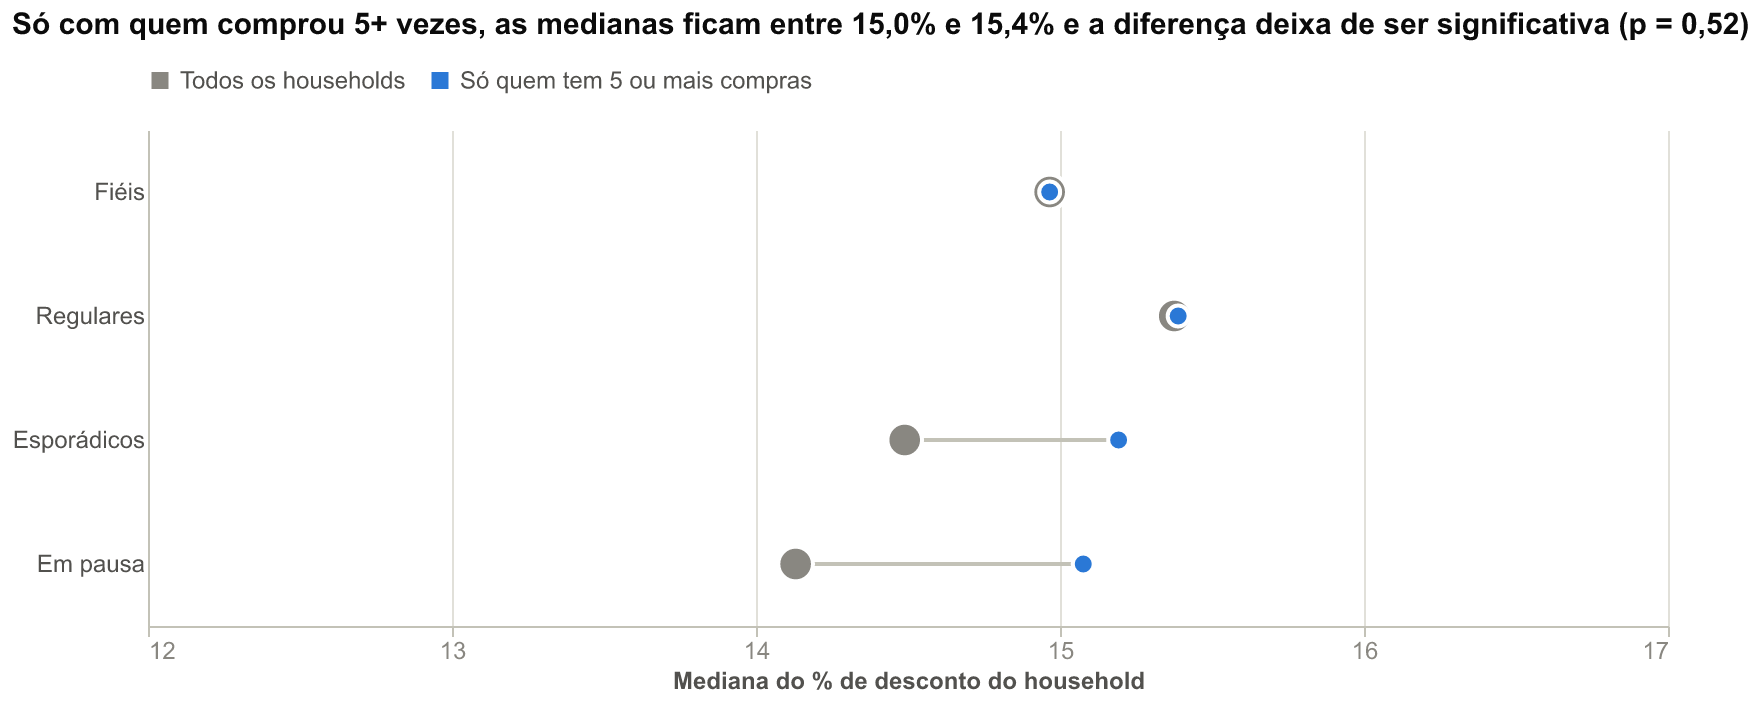

In [35]:
s = desc["sensibilidade"]
na.md(f"Com {na.milhar(s['households'])} households de {s['minimo_compras']} ou mais compras (de {na.milhar(desc['households'])}): p = {na.pt(s['kruskal_wallis']['p_valor'], 4)}, "
      f"eta² = {na.pt(max(0.0, s['kruskal_wallis']['eta_quadrado_aprox']), 4)}, veredito **{VEREDITO[s['veredito']]}**. "
      "Quando a significância some ao tirar o ruído de poucas cestas, a diferença do teste completo não é uma política diferente por segmento.")
na.grafico(graficos.grafico_sensibilidade(desc["grupos"], s["grupos"], s["minimo_compras"], s["kruskal_wallis"]["p_valor"], s["veredito"], na.MODO))

In [36]:
na.e_dai(desc["e_dai"])

> **E daí?**
>
> **Conclusão.** Os segmentos recebem desconto praticamente igual: as medianas vão de 14,1% (Em pausa) a 15,4% (Regulares), 1,2 ponto percentual de amplitude. O teste geral acusa diferença (p = 0,009), mas o efeito é desprezível: eta² = 0,0036, ou 0,4% da variação, e todos os intervalos das diferenças de mediana ficam abaixo de 1 ponto ou incluem zero. Só com households de 5 ou mais compras (2.138) a significância desaparece (p = 0,523, eta² = 0,0000): a diferença do teste completo vem do ruído de medir desconto em poucas compras.
>
> **Ação recomendada.** Tratar o desconto como política geral, não por segmento: a diferença estatística existe só no papel e não justifica ajustar taxa para nenhum grupo. Para mexer na margem, olhar o desconto como um todo ou por categoria (não testado aqui).
>
> **Impacto estimado.** Desconto total da janela: US$ 399.892 (15,7% do valor bruto). Se todos os segmentos tivessem a menor taxa ponderada (Fiéis, 15,45%), o desconto cairia US$ 5.607 (1,4% do total), supondo que a demanda não mudasse.
>
> **Limitações.** Diferença entre grupos, não efeito causal do desconto: o teste não diz que desconto traz mais compra. Os segmentos são definidos por recência, frequência e valor, e o % de desconto de quem comprou pouco é instável (poucas cestas), o que aumenta a dispersão dos grupos Esporádicos e Em pausa; por isso a repetição com 5 ou mais compras (nela os Em pausa ficam com 45 households). Uma só janela de 26 semanas. Desconto de loja (cartão) e de cupom estão somados. Os p-valores dos pares são ajustados por Holm; os intervalos de confiança das diferenças não. Household não é pessoa. Households sem compra na janela ficam fora.

## 7. Costura: a narrativa das quatro análises

As quatro análises respondem perguntas em sequência: **quem são** (RFM), **quanto valem** (CLV), **o que vai acontecer** (risco de pausa) e **por que diferem** (desconto). A tabela junta o que cada uma diz sobre cada segmento.
Células vazias são esperadas: "Em pausa" e "Sem compra" já pausaram, então não entram na previsão de pausa; "Sem compra na janela" não é segmento do RFM.

In [37]:
base = pd.DataFrame({"Segmento": [s["nome"] for s in seg["segmentos"]] + ["Sem compra na janela"]})
rfm_ = pd.DataFrame([{"Segmento": s["nome"], "Households": s["households"], "% do faturamento": s["pct_faturamento"]} for s in seg["segmentos"]])
clv_ = pd.DataFrame([{"Segmento": s["nome"], "CLV por household (US$)": s["clv_medio"], "Margem esperada (US$)": s["clv_total_usd"]} for s in clv["segmentos"]])
risco_ = pd.DataFrame([{"Segmento": s["nome"], "Risco de pausa em 8 semanas (%)": s["risco_medio_pct"], "Valor em risco (US$)": s["valor_em_risco_usd"]} for s in churn["risco_por_segmento"]])
desc_ = pd.DataFrame([{"Segmento": g["segmento"], "Mediana de desconto (%)": g["mediana_pct"], "Taxa ponderada (%)": g["taxa_ponderada_pct"]} for g in desc["grupos"]])
costura = base
for parte in (rfm_, clv_, risco_, desc_):
    costura = costura.merge(parte, on="Segmento", how="left")
casas = {"Households": 0, "% do faturamento": 1, "CLV por household (US$)": 0, "Margem esperada (US$)": 0, "Risco de pausa em 8 semanas (%)": 1,
         "Valor em risco (US$)": 0, "Mediana de desconto (%)": 1, "Taxa ponderada (%)": 1}
costura = costura.astype(object)
for coluna, n in casas.items():
    costura[coluna] = costura[coluna].map(lambda v: "" if pd.isna(v) else (int(round(v)) if n == 0 else round(float(v), n)))
costura

,Segmento,Households,% do faturamento,CLV por household (US$),Margem esperada (US$),Risco de pausa em 8 semanas (%),Valor em risco (US$),Mediana de desconto (%),Taxa ponderada (%)
0,Fiéis,857,70.9,820,702528,0.6,2517,15.0,15.5
1,Regulares,980,25.9,326,319094,4.5,7157,15.4,16.2
2,Esporádicos,426,2.5,135,57544,22.9,3031,14.5,16.7
3,Em pausa,158,0.7,103,16235,,,14.1,16.2
4,Sem compra na janela,,,99,7820,,,,


In [38]:
fieis, regulares, esporadicos = seg["segmentos"][0], seg["segmentos"][1], seg["segmentos"][2]
r_por = {s["nome"]: s for s in churn["risco_por_segmento"]}
clv_por = {s["nome"]: s for s in clv["segmentos"]}
total_vr = sum(s["valor_em_risco_usd"] for s in churn["risco_por_segmento"])
na.md(f"""**O que as quatro análises dizem juntas**

1. **Poucos clientes carregam o negócio.** Os {fieis['nome']} são {na.pt(fieis['pct_households'], 0)}% dos households e fazem {na.pt(fieis['pct_faturamento'], 0)}% do faturamento; cada um vale cerca de {na.usd(clv_por[fieis['nome']]['clv_medio'])} de margem esperada em 52 semanas.
2. **O risco de pausa está onde o cliente vale menos; o dinheiro em risco está no meio.** Os {esporadicos['nome']} têm {na.pt(r_por[esporadicos['nome']]['risco_medio_pct'], 1)}% de risco, mas os {regulares['nome']} concentram
   {na.pt(100 * r_por[regulares['nome']]['valor_em_risco_usd'] / total_vr, 0)}% do valor em risco ({na.usd(r_por[regulares['nome']]['valor_em_risco_usd'])} em 8 semanas), porque são muitos e gastam bem mais.
3. **A maioria das pausas é temporária** ({na.pt(churn['retorno_apos_pausa']['taxa_pct'], 0)}% voltam em {churn['retorno_apos_pausa']['janela_semanas']} semanas): reativação deve ser barata e seletiva, não uma campanha para todos.
4. **O desconto não explica a diferença entre os grupos.** Os segmentos recebem desconto praticamente igual ({VEREDITO[desc['veredito']]}); portanto, não há base nestes dados para uma política de desconto por segmento.
   Isto *não* diz que o desconto não influencia a compra: o teste compara grupos, não mede o efeito de dar desconto.""")

**O que as quatro análises dizem juntas**

1. **Poucos clientes carregam o negócio.** Os Fiéis são 35% dos households e fazem 71% do faturamento; cada um vale cerca de US$ 820 de margem esperada em 52 semanas.
2. **O risco de pausa está onde o cliente vale menos; o dinheiro em risco está no meio.** Os Esporádicos têm 22,9% de risco, mas os Regulares concentram
   56% do valor em risco (US$ 7.157 em 8 semanas), porque são muitos e gastam bem mais.
3. **A maioria das pausas é temporária** (80% voltam em 18 semanas): reativação deve ser barata e seletiva, não uma campanha para todos.
4. **O desconto não explica a diferença entre os grupos.** Os segmentos recebem desconto praticamente igual (diferença desprezível); portanto, não há base nestes dados para uma política de desconto por segmento.
   Isto *não* diz que o desconto não influencia a compra: o teste compara grupos, não mede o efeito de dar desconto.

### Ações, em ordem de prioridade

1. **Proteger os Fiéis:** monitorar queda de frequência (a constância de compra é o sinal que mais protege contra a pausa) antes de qualquer outra ação.
2. **Priorizar a reativação pelos Regulares em alerta**, onde está o maior valor em risco, e depois pelos Esporádicos, onde o risco é maior mas o valor por cliente é baixo. Usar o limiar do modelo para decidir quantos contatar:
   o gráfico de precisão e recall mostra a troca.
3. **Não diferenciar desconto por segmento** com base nestes dados; se a margem for o problema, olhar o desconto como um todo ou por categoria.

### O que estes dados não permitem afirmar

- **Nada é causal.** Segmentos descrevem comportamento; fatores do modelo são associação; a diferença de desconto entre grupos não mede o efeito do desconto sobre a compra.
- **Painel pequeno e frequente.** São 2.500 households que compram com regularidade, não o cliente médio do varejista. Resultados por loja ou categoria pequena são instáveis.
- **A margem é uma premissa** (25%): o CLV em dólares muda proporcionalmente; o ranking entre grupos, não.
- **Uma só janela de 26 semanas** e um só ano de comparação; as datas reais são arbitrárias, então sazonalidade por data não é medida.
- **O horizonte de 52 semanas do CLV não tem backtest**, e o CLV não serve como previsão por cliente.
- **Precisão por alerta modesta** no risco de pausa: o modelo ordena bem (AUC), mas a maioria dos alertas não se confirma; ele serve para priorizar, não para decidir sozinho.
- **Desconto de loja (cartão) e de cupom estão somados.** Separá-los é um próximo passo possível.

### Próximos passos possíveis

- Separar o desconto de loja do de cupom por segmento.
- Repetir as análises em outra janela e verificar se os segmentos e o risco se mantêm.
- Substituir a margem de 25% pela margem real por categoria, se o varejista a fornecer.
- *Market Basket* (associação entre produtos) ficou de fora de propósito: é uma análise à parte, não um pilar desta narrativa.

## 8. Reprodutibilidade

Um comando por etapa, semente fixa em tudo que é aleatório e parâmetros num único `config.yaml`. A célula abaixo ainda faz uma conferência final: **sobe o servidor MCP** (o mesmo que atende o app e o Claude Desktop)
e confirma que as quatro análises dão **exatamente os mesmos números** pelo servidor e aqui no notebook.

In [39]:
from src.cliente_mcp import ServidorMCP

servidor = ServidorMCP(caminho_banco=raiz / CFG["banco"]["arquivo"])
try:
    via_mcp = {nome: servidor.chamar(nome) for nome in ("segmentar_clientes", "calcular_clv", "prever_churn", "testar_desconto_entre_segmentos")}
finally:
    servidor.fechar()
aqui = {"segmentar_clientes": seg, "calcular_clv": clv, "prever_churn": churn, "testar_desconto_entre_segmentos": desc}
import json
iguais = {n: json.loads(json.dumps(aqui[n], ensure_ascii=False, default=str)) == via_mcp[n] for n in aqui}
assert all(iguais.values()), f"notebook e servidor MCP divergem: {iguais}"
na.md("**Notebook e servidor MCP dão o mesmo resultado, campo a campo:** " + ", ".join(f"`{n}` ✓" for n in iguais) + f" (base `{versao}`).")

**Notebook e servidor MCP dão o mesmo resultado, campo a campo:** `segmentar_clientes` ✓, `calcular_clv` ✓, `prever_churn` ✓, `testar_desconto_entre_segmentos` ✓ (base `ddb4d8032cc2`).

In [40]:
na.md("**Versões das bibliotecas que determinam os números:** " + ", ".join(f"{p} {v}" for p, v in na.versoes().items()) + f". Python {sys.version.split()[0]}. Semente: {CFG['semente']}.")
na.md("""```
venv\\Scripts\\python.exe -m pip install -r requirements.txt     # versões travadas
venv\\Scripts\\python.exe baixar_dados.py                         # baixa data/raw/ (precisa de credencial do Kaggle)
venv\\Scripts\\python.exe -m src.etl                              # ETL: data/processed/dunnhumby.duckdb + relatorios/qualidade.md (~2 min)
venv\\Scripts\\python.exe notebooks\\construir_notebook.py          # reexecuta este notebook e salva com as saídas
venv\\Scripts\\python.exe -m pytest tests -q                      # testes (em partes: veja o CLAUDE.md)
```""")

**Versões das bibliotecas que determinam os números:** duckdb 1.5.6, pandas 3.0.6, numpy 2.5.3, scikit-learn 1.9.1, scipy 1.18.1, statsmodels 0.15.0, altair 6.3.0. Python 3.14.7. Semente: 42.

```
venv\Scripts\python.exe -m pip install -r requirements.txt     # versões travadas
venv\Scripts\python.exe baixar_dados.py                         # baixa data/raw/ (precisa de credencial do Kaggle)
venv\Scripts\python.exe -m src.etl                              # ETL: data/processed/dunnhumby.duckdb + relatorios/qualidade.md (~2 min)
venv\Scripts\python.exe notebooks\construir_notebook.py          # reexecuta este notebook e salva com as saídas
venv\Scripts\python.exe -m pytest tests -q                      # testes (em partes: veja o CLAUDE.md)
```